# QC0426 — Measure

`metadata.hera.policy` — scientific record: append new cells; never edit or
delete executed ones. (Who *executes* a measure cell is set by the session
mode — see the brief.)

Confirm each `# <-- verify` (rig: addresses) and `# <-- validate` (device:
operating limits, wiring) line at bring-up. Cells marked **PATTERN** /
**PROPOSAL** carry `<PLACEHOLDER>` values — review before running.

## Setup

In [1]:
import os
import time

import numpy as np
import scipy.constants as cst

import qcodes
from qcodes import validators
from qcodes.instrument_drivers.stanford_research import SR830
from qcodes.instrument_drivers.tektronix.Keithley_2400 import Keithley_2400

import sweep
from sweep import interruptible_sleep
from gui.qt_progress import QtProgress
sweep.set_progress(QtProgress())

from hera.analysis import GateCalibration, field_invB
from sharpelab_nb.constants import VTI
from sharpelab_nb.thermometry import temperature_from_logfiles

from drivers.FastBi1K5 import FastBi1K5
from drivers.Lakeshore_335 import Lakeshore_335
from drivers.SRS_DC205 import SRS_DC205

In [2]:
main_dir = os.getcwd()
sweep.set_basedir(os.path.join(main_dir, "data"))
main_dir

'C:\\Users\\DGG\\VTI_local_data\\zack\\20260718-QC0426'

# Connect Instruments

## Magnet

In [3]:
magnet = FastBi1K5('magnet', '192.168.0.10')  # <-- verify address
magnet.status()

Connected to: Fast-Bi-1K5 Magnet Controller
---------- Magnet Status ----------
Field:               : 0.003 Tesla
Current:             : 0.025 A
Voltage:             : -0.000 V
Output Enabled       : True
Persistent Switch On : True
Loop Mode            : CC
Update Mode          : NORMAL
-----------------------------------


## Lakeshore

In [4]:
# heater: LS335 control only (setpoints / ranges / heater power). The lakeshore
# worker (VTI Monitor launcher) is the sole GPIB master on the LS335; per-point
# temperature is read from its logfiles, never over GPIB. fp() these params.
heater = Lakeshore_335('l335_3', 'GPIB0::10::INSTR')

T_sample = temperature_from_logfiles("T_sample", VTI.temp_logfile_candidates["T_sample"])
T_vaporizer = temperature_from_logfiles("T_vaporizer", VTI.temp_logfile_candidates["T_vaporizer"])

print(f"Sample:    {T_sample()} K")
print(f"Vaporizer: {T_vaporizer()} K")

Connected to: LSCI 335 (serial:LSA2FM7/#######, firmware:1.4) in 0.11s
Sample:    1.176 K
Vaporizer: 0.951 K


## Lock-ins

In [5]:
sr0 = SR830('sr0', "GPIB0::17::INSTR")  # <-- verify — current channel (Ithaco preamp output)
sr1 = SR830('sr1', "GPIB0::14::INSTR")  # <-- verify — also the AC drive source
sr2 = SR830('sr2', "GPIB0::19::INSTR")  # <-- verify
sr3 = SR830('sr3', "GPIB0::18::INSTR")  # <-- verify

Connected to: Stanford_Research_Systems SR830 (serial:s/n45620, firmware:ver1.07) in 0.08s
Connected to: Stanford_Research_Systems SR830 (serial:s/n83412, firmware:ver1.07) in 0.08s


C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.p

Connected to: Stanford_Research_Systems SR830 (serial:s/n41639, firmware:ver1.07) in 0.08s
Connected to: Stanford_Research_Systems SR830 (serial:s/n93552, firmware:ver1.07) in 0.08s


C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(


## Keithleys

In [6]:
k_2400_tg = Keithley_2400('k_2400_tg', 'GPIB0::24::INSTR')  # <-- verify address — top-gate Keithley
# k_2400_tg.mode.set('VOLT')
# k_2400_tg.volt.set(0)
# k_2400_tg.rangei.set(1e-6)
# k_2400_tg.rangev.set(21)
k_2400_tg.volt.step = 0.005
k_2400_tg.nplci.set(1)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:0734554, firmware:C17   Jul 16 1999 15:20:40/A02  /G/F) in 0.03s


In [7]:
k_2400_bg = Keithley_2400('k_2400_bg', 'GPIB0::1::INSTR')  # <-- verify address — back-gate Keithley
# k_2400_bg.mode.set('VOLT')
# k_2400_bg.volt.set(0)
# k_2400_bg.rangei.set(1e-6)
# k_2400_bg.rangev.set(21)
k_2400_bg.volt.step = 0.005
k_2400_bg.nplci.set(1)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:1225634, firmware:C30   Mar 17 2006 09:29:29/A02  /K/J) in 0.03s


## DC205 (Si gate)

In [8]:
dc205 = SRS_DC205("dc205", "ASRL7::INSTR")  # <-- verify address — Si-gate DC205
# Si window is ±50 V ⇒ DC205 must be on its ±100 V range (RNGE 2). Range
# changes require output OFF (front panel) — surface a mismatch, don't force it.
print(f"range code: {dc205.voltage_range()} (need 2 = ±100 V)")
print(f"output on:  {dc205.output()}")
dc205.ramp_rate = 0.5  # V/s — Si dielectric pacing; consent-gated    # <-- validate

Connected to: Stanford_Research_Systems DC205 (serial:s/n20500514, firmware:ver1.80) in 0.04s
range code: 2 (need 2 = ±100 V)
output on:  1


In [9]:
# slot: gate-bindings — role aliases (k_tg/k_bg/k_si) from the device card's
# Gate stack section (which instrument drives which gate). Each value
# `# <-- validate`.

# Gate role aliases (recipes use k_tg / k_bg / k_si):
k_tg = k_2400_tg   # top gate  <- Keithley 2400 (fast axis k_tg.volt)   # <-- validate
k_bg = k_2400_bg   # back gate <- Keithley 2400                          # <-- validate
# Si gate <- the driver's ramped parameter: set ramps at dc205.ramp_rate,
# get reads back VOLT?. Data column 'dc205_smart_voltage'. No current readback.
k_si = dc205.smart_voltage   # <-- validate

# SAFETIES

Run immediately after instrument bring-up, before any sweep.

In [10]:
# slot: gate-validators — operating limits from the device card's gate-
# operating-limits table; commit EXACTLY the card numbers. Each value
# `# <-- validate`. Instrument-level fences go on the RAW instruments
# (k_2400_tg / k_2400_bg / dc205); direct calls bypass the role-alias wrapper.
TG_MIN, TG_MAX = -3.0, +3.0    # top gate (k_2400_tg), V     # <-- validate
BG_MIN, BG_MAX = -4.5, +4.5    # back gate (k_2400_bg), V    # <-- validate
SI_MIN, SI_MAX = -50.0, +50.0  # Si gate (dc205), V          # <-- validate
k_2400_tg.volt.vals = validators.Numbers(TG_MIN, TG_MAX)
k_2400_bg.volt.vals = validators.Numbers(BG_MIN, BG_MAX)
dc205.smart_voltage.vals = validators.Numbers(SI_MIN, SI_MAX)  # k_si sets go through this
dc205.voltage.vals = validators.Numbers(SI_MIN, SI_MAX)  # instrument-level: ramp_voltage sets via dc205.voltage, so this fences ramps too

# Limit lists for sanitize_tg_bg()
tg_lims, bg_lims = [TG_MIN, TG_MAX], [BG_MIN, BG_MAX]

# Session field cap — machine-enforced: magnet.field is a qcodes Parameter,
# so this validator rejects any magnet.field(target) with |B| > B_SESSION_CAP
# before any hardware traffic (and the non-blocking start_field_ramp re-checks
# it too). (Driver max_field_T = 14.0 remains as backstop.)
B_SESSION_CAP = 8.0  # Tesla    # <-- validate (session cap from card/brief)
magnet.field.vals = validators.Numbers(-B_SESSION_CAP, B_SESSION_CAP)

# Temperature setpoint cap — card-provided session cap committed as the SAFETIES
# setpoint typo-guard (card: set_both target <= 100 K).
T_SESSION_CAP = 100.0  # K    # <-- validate (card: set_both target <= 100 K)
heater.sample_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)
heater.vaporizer_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)


# Helpers

In [11]:
def spoints(a, b, c):
    return np.linspace(a, b, c)


def sanitize_tg_bg(vtg_vec, vbg_vec, tg_lims, bg_lims):
    """
    Given a list of tg and bg voltages, removes any points which are outside tg_lims and bg_lims
    """
    vtg_new_vec = []
    vbg_new_vec = []
    for ind in range(len(vtg_vec)):
        vtg, vbg = vtg_vec[ind], vbg_vec[ind]
        if vtg < tg_lims[0] or vtg > tg_lims[1] or vbg < bg_lims[0] or vbg > bg_lims[1]:
            pass
        else:
            vtg_new_vec.append(vtg)
            vbg_new_vec.append(vbg)
    return np.array(vtg_new_vec), np.array(vbg_new_vec)

In [12]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 15.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 12e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

# Measurement config

In [13]:
# slot: meas-config — sr0_gain + channel/contact assignments from the device
# card's Measurement setup (current channel + gain, provided contact
# configuration). Each value `# <-- validate`. Always set 'comments' per run —
# structured, current, no inherited text. Lock-in state (amplitude, freq,
# sens, tau) is NOT recorded here — sweep snapshots followed instruments
# live at each run start; bias_channel tells hera-watch where the drive is.
meas_config = {
    "source": "T2",  # drive injection contact    # <-- validate
    "sr0": "drain current on B7",  # <-- validate
    "sr0_gain": -1e6,  # ithaco gain    # <-- validate
    "sr1": "T3-T4",  # Rxx    # <-- validate
    "sr2": "B4-B5",  # Rxx    # <-- validate
    "sr3": "T5-B6",  # Rxy (Hall)    # <-- validate
    "bias_resistor": 100e6,
    "bias_channel": "sr1",  # drive lock-in; I_bias = its live amplitude / bias_resistor (auto-snapshotted)    # <-- validate
    "sample_temperature:": T_sample(),  # file-based (worker logfile), not in instrument snapshots; key verbatim (trailing ':') to match this cooldown's metadata
    "Si (V)": dc205.voltage(),  # not snapshotted unless followed — re-run this cell after moving Si
    "comments": "<SET PER RUN>",
}


## Contacts — hardwired (no mux this cooldown)

No QSwitch/ContactMux in the loop: contact roles are fixed at the breakout.
The map below is documentation from the device card's provided contact
configuration; changing a pair is operator work at the breakout, not software.

In [14]:
# slot: contact-map — hardwired role -> contact map from the device card's
# provided contact configuration. Documentation only (no mux to drive);
# each value `# <-- validate`.
WIRING = {  # <-- validate (from card provided contact configuration)
    "source": "T2", "drain": "B7",
    "sr1+": "T3", "sr1-": "T4",
    "sr2+": "B4", "sr2-": "B5",
    "sr3+": "T5", "sr3-": "B6",
}

# HERA — QC0426 session start (2026-07-18)

## HERA — kernel probe + VERIFY (grant gate)

Gates A and B read green from the notebook: setup executed with sane readbacks (magnet 0.003 T, PS on / output enabled; T_sample 1.176 K; 4× SR830, 2× Keithley, DC205 RNGE 2 / output on), and the SAFETIES cell ran with exactly the device-card numbers (TG ±3.0 V, BG ±4.5 V, Si ±50 V, |B| ≤ 8.0 T, set_both ≤ 100 K).

Two cells follow, per the brief's grant protocol — **neither runs until the operator says "go for autonomy"**; they are then my first E1 acts, in order:

1. **Kernel probe** — read-only namespace check that execute-cell is bound to this instrument-carrying kernel.
2. **VERIFY** — the brief's session-start checklist, read-only by construction: magnet at zero (both readback surfaces), committed validators re-compared against the card numbers, base T, heaters off + vaporizer at base, lakeshore-worker logfile advancing on the 5 s cadence (16 s mtime poll — the runtime of this cell), He level (AMI 1700, read-only query), hardwired contact map vs the card, DC205 range/output/0 V. Last output line is the machine-read verdict: `VERIFY: ALL GREEN` engages E1; any `VERIFY: FAIL <item>` voids the grant and I stay in E0.

Runtime ≈ 20 s. No instrument writes anywhere in either cell.


In [15]:
# KERNEL PROBE — read-only namespace check (first E1 act, pre-VERIFY).
# Confirms nb-collab execute-cell is bound to the operator's instrument-carrying
# kernel, not a fresh one. No instrument I/O beyond qcodes bookkeeping.
_need = ["magnet", "heater", "sr0", "sr1", "sr2", "sr3",
         "k_2400_tg", "k_2400_bg", "dc205", "k_tg", "k_bg", "k_si",
         "T_sample", "T_vaporizer", "cal", "meas_config", "WIRING"]
_missing = [n for n in _need if n not in globals()]
_live = sorted(qcodes.Instrument._all_instruments.keys())
print(f"bound instruments: {_live}")
print(f"missing names: {_missing if _missing else 'none'}")
if _missing:
    print("KERNEL PROBE: FAIL — not the instrument-carrying kernel")
else:
    print("KERNEL PROBE: OK — bound to the instrument-carrying kernel")


bound instruments: ['dc205', 'k_2400_bg', 'k_2400_tg', 'l335_3', 'magnet', 'sr0', 'sr1', 'sr2', 'sr3']
missing names: none
KERNEL PROBE: OK — bound to the instrument-carrying kernel


In [16]:
# VERIFY — session-start checks (brief: [VERIFY] at session start).
# Read-only by construction: getters and file stats only — no sets, no ramps,
# no heater/gate/field writes. Runtime ~20 s (worker-cadence poll dominates).
# The E1 grant keys on the printed verdict line at the end of this cell.
import os
import time

_fails = []

def _chk(name, ok, detail):
    if not ok:
        _fails.append(name)
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: {detail}")

# --- 1. Magnet at 0 T (measured readback, both surfaces) ---
_B = magnet.field()
_B_stat = magnet._status()["field"]
_chk("magnet-zero", abs(_B) <= 0.02 and abs(float(_B_stat)) <= 0.02,
     f"field()={_B:+.4f} T, _status[field]={_B_stat}")
_chk("magnet-output",
     magnet.persistent_switch_on() and magnet.output_enabled(),
     f"PS heater on={magnet.persistent_switch_on()}, output={magnet.output_enabled()}")

# --- 2. SAFETIES committed == device card (independent re-statement of the
#        card numbers — compares the live validators, not the notebook vars) ---
def _vr(p):
    v = p.vals
    return (float(v._min_value), float(v._max_value))

_card = {
    "tg-validator":  (k_2400_tg.volt,        (-3.0, 3.0)),
    "bg-validator":  (k_2400_bg.volt,        (-4.5, 4.5)),
    "si-validator":  (dc205.smart_voltage,   (-50.0, 50.0)),
    "si-raw-validator": (dc205.voltage,      (-50.0, 50.0)),
    "field-cap":     (magnet.field,          (-8.0, 8.0)),
    "t-cap-sample":  (heater.sample_setpoint,    (0.0, 100.0)),
    "t-cap-vaporizer": (heater.vaporizer_setpoint, (0.0, 100.0)),
}
for _name, (_p, _exp) in _card.items():
    try:
        _got = _vr(_p)
        _chk(_name, _got == _exp, f"committed {_got}, card {_exp}")
    except Exception as _e:
        _chk(_name, False, f"validator unreadable: {_e!r}")

# --- 3. Base T holding ---
_Ts = T_sample()
_chk("base-T", 1.0 <= _Ts <= 1.5, f"T_sample = {_Ts:.3f} K (base ~= 1.2-1.3 K)")

# --- 4. Heaters off, vaporizer tracking base ---
_rs, _rv = heater.sample_range(), heater.vaporizer_range()
_chk("heaters-off", _rs == 0 and _rv == 0, f"sample_range={_rs}, vaporizer_range={_rv}")
_Tv = T_vaporizer()
_chk("vaporizer-base", _Tv < 2.0, f"T_vaporizer = {_Tv:.3f} K")

# --- 5. Lakeshore worker logfile: mtime advancing on the 5 s cadence.
#        Poll 16 s at 0.5 s; a 5 s worker shows >=2 mtime changes, the stale
#        30 s worker <=1 (rig card: threshold must allow >=2-3 write periods). ---
_cands = [p for p in VTI.temp_logfile_candidates["T_sample"] if os.path.exists(p)]
if not _cands:
    _chk("worker-cadence", False, "no T_sample logfile found")
else:
    _lf = _cands[0]
    _mt, _changes = os.path.getmtime(_lf), 0
    for _ in range(32):
        interruptible_sleep(0.5)
        _m = os.path.getmtime(_lf)
        if _m != _mt:
            _changes += 1
            _mt = _m
    _age = time.time() - _mt
    _chk("worker-cadence", _changes >= 2,
         f"{_changes} writes in 16 s, last write {_age:.1f} s ago ({_lf})")

# --- He level (AMI 1700, read-only query; closed-loop system per rig card,
#     so this is bath-presence/sensor-alive, not a consumption budget) ---
try:
    try:
        _ami = qcodes.Instrument.find_instrument("ami")
    except Exception:
        from drivers.AMI_1700 import AMI_1700
        _ami = AMI_1700("ami", "TCPIP0::192.168.0.100::7180::SOCKET")
    _he = _ami.He_level()
    _chk("he-level", _he > 0, f"{_he:.1f} in (closed-loop rig; operator judges margin)")
except Exception as _e:
    _chk("he-level", False, f"AMI 1700 read failed: {_e!r}")

# --- 6. Contacts hardwired per the device card's provided configuration ---
_exp_wiring = {"source": "T2", "drain": "B7", "sr1+": "T3", "sr1-": "T4",
               "sr2+": "B4", "sr2-": "B5", "sr3+": "T5", "sr3-": "B6"}
_chk("contact-config", WIRING == _exp_wiring, f"WIRING == card: {WIRING == _exp_wiring}")

# --- 7. DC205 on +/-100 V range, output on, reading 0 V ---
_rng, _out, _V = dc205.voltage_range(), dc205.output(), dc205.voltage()
_chk("dc205", int(_rng) == 2 and int(_out) == 1 and abs(_V) <= 0.05,
     f"range={_rng} (need 2), output={_out}, V={_V:+.4f}")

# --- Verdict (machine-read; last line of output) ---
if _fails:
    print(f"VERIFY: FAIL {_fails[0]}" + (f" (+{len(_fails)-1} more: {', '.join(_fails[1:])})" if len(_fails) > 1 else ""))
else:
    print("VERIFY: ALL GREEN")


[PASS] magnet-zero: field()=+0.0034 T, _status[field]=0.003403506849315068
[PASS] magnet-output: PS heater on=True, output=True
[PASS] tg-validator: committed (-3.0, 3.0), card (-3.0, 3.0)
[PASS] bg-validator: committed (-4.5, 4.5), card (-4.5, 4.5)
[PASS] si-validator: committed (-50.0, 50.0), card (-50.0, 50.0)
[PASS] si-raw-validator: committed (-50.0, 50.0), card (-50.0, 50.0)
[PASS] field-cap: committed (-8.0, 8.0), card (-8.0, 8.0)
[PASS] t-cap-sample: committed (0.0, 100.0), card (0.0, 100.0)
[PASS] t-cap-vaporizer: committed (0.0, 100.0), card (0.0, 100.0)
[PASS] base-T: T_sample = 1.175 K (base ~= 1.2-1.3 K)
[PASS] heaters-off: sample_range=0, vaporizer_range=0
[PASS] vaporizer-base: T_vaporizer = 0.950 K


[PASS] worker-cadence: 3 writes in 16 s, last write 4.9 s ago (C:\Users\DGG\temperature_logs\VTI_sample.txt)
[PASS] he-level: 16.1 in (closed-loop rig; operator judges margin)
[PASS] contact-config: WIRING == card: True
[PASS] dc205: range=2 (need 2), output=1, V=+0.0000
VERIFY: ALL GREEN


## HERA — Gate C: gate-current-sanity-check (first-session liveness)

Recipe: `device-init/gate-current-sanity-check.md` — first-session branch, no designated references (strict data isolation), so the 1D gate-response legs are judged on their own terms per `reentry-baseline` step 3.

**What:** four legs, one run each — `k_tg` 0 → +3.0 / 0 → −3.0 V, `k_bg` 0 → +4.5 / 0 → −4.5 V (endpoints are the committed card limits; nothing hand-substituted), the other gate parked at 0, Si (DC205) parked at 0 V throughout (contact-doping gate, screened from the channel, no current readback; its survey is blocklisted). Gate-current channels at `nplci=10` for pA readback; the reset cell below restores `nplci=1` and runs **only after all four legs read clean from disk**.

**Read per leg:** lock-in X nonzero and smoothly varying → alive; swept-gate current pA-scale on the capacitive charging slope → safe; parked-gate current at floor → no cross-gate path. Any gross turn-up off the charging slope → interrupt (the `try/finally` parks the gate), stop and report.

**Drive/sens:** card starting points — sr1 drive 0.5 V through 100 MΩ (5 nA), voltage channels 2e-5, sr0 1e-2. Preconditions asserted in-cell: base T, B ≈ 0, Si at 0.

**Price:** ~2.1 s/pt at nplci=10 (rig card, 20260714.2 runs 0–3 class) × 251 pts × 4 legs ≈ **35–42 min** total. Checkpoints: first rows of each leg via `hera-watch` (leakage / dead channel / clipping — cheapest kill), then per-leg completion digests. E1 auto-bucket: in-envelope, inside committed validators.


preconditions: T_sample=1.176 K (expect 1.0-1.5), B=+0.0034 T (expect ~0), V_si=+0.000 V (expect 0)
sr0: tau=0.3 s, slope=24 dB/oct, sens(pre)=0.05
sr1: tau=0.3 s, slope=24 dB/oct, sens(pre)=0.0001
sr2: tau=0.3 s, slope=24 dB/oct, sens(pre)=5e-05
sr3: tau=0.3 s, slope=24 dB/oct, sens(pre)=0.0001


2026-07-18 21:40:17,716 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-07-18 21:40:18,241 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-07-18 21:40:18,258 [INFO] Starting sweep with ID 0


2026-07-18 21:40:18,259 [INFO] Minimum duration 0h 4m 11s


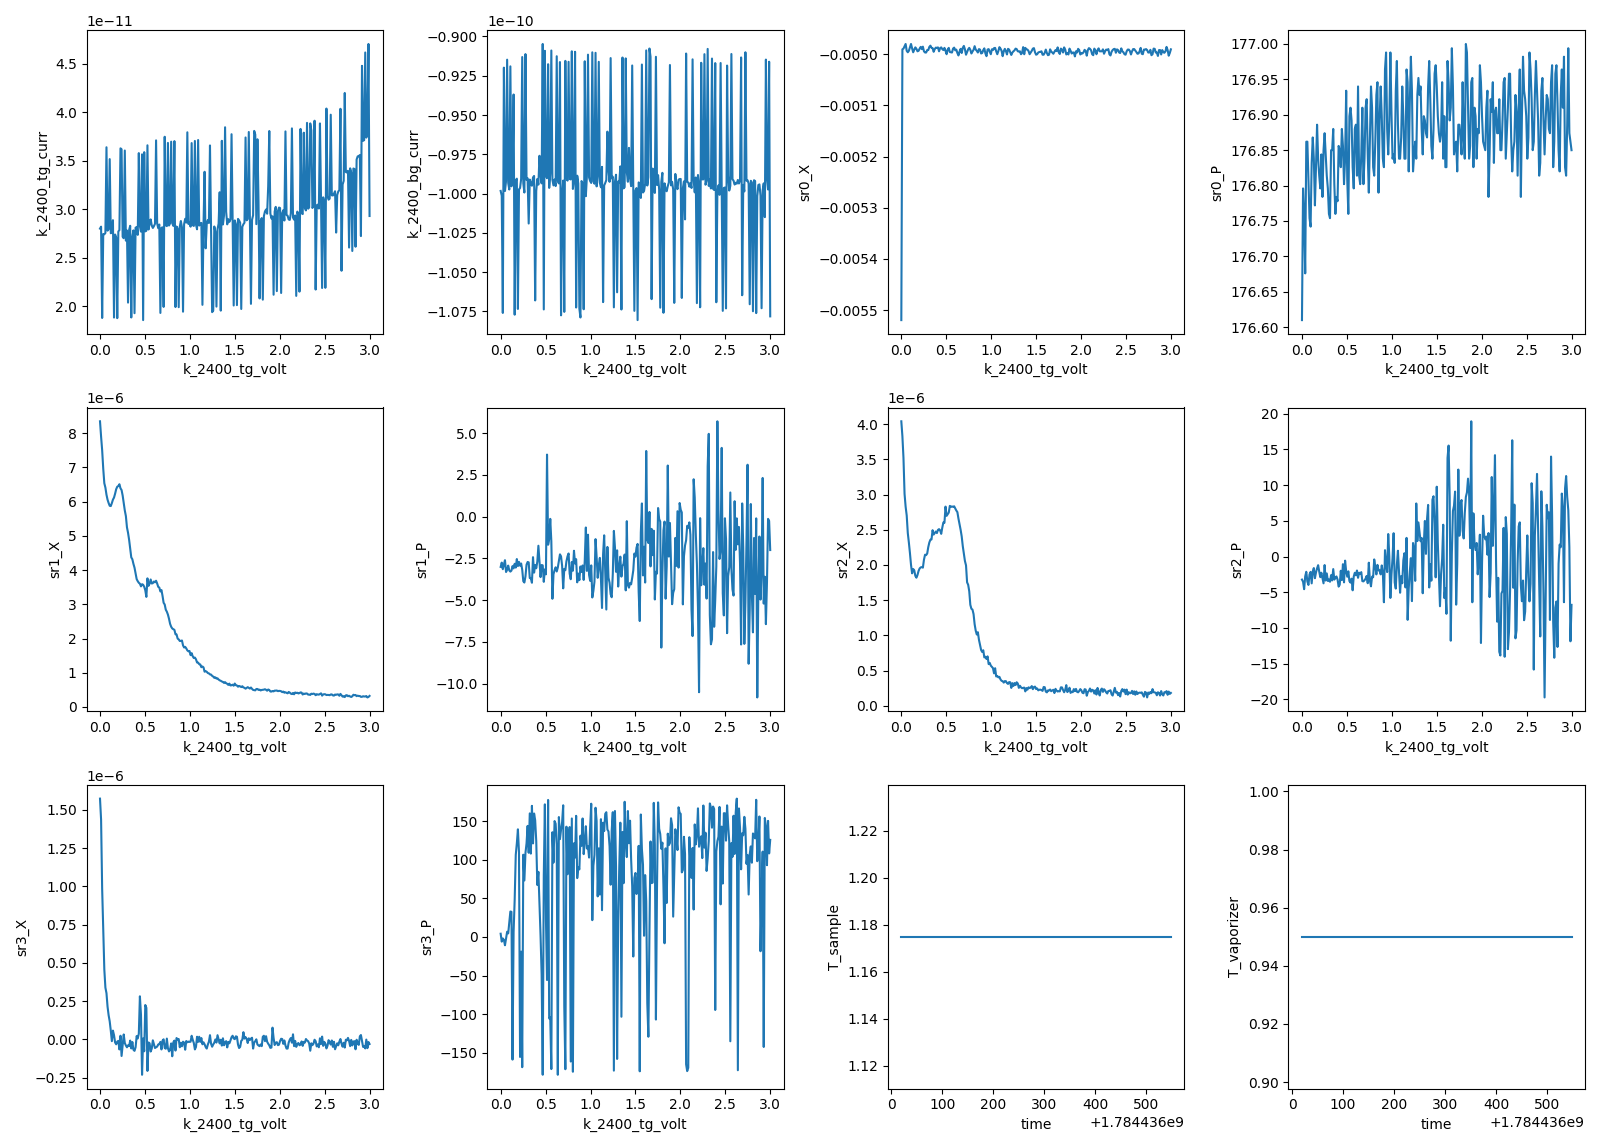

2026-07-18 21:49:10,017 [INFO] Completed in 0h 8m 50s


2026-07-18 21:49:10,018 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260718-QC0426\data\0\data.tsv.gz


2026-07-18 21:49:10,530 [INFO] Ramping k_2400_tg_volt: 3.0 -> 0


leg done: k_2400_tg 0 -> +3 V


2026-07-18 21:49:14,822 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-07-18 21:49:15,345 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-07-18 21:49:15,359 [INFO] Starting sweep with ID 1


2026-07-18 21:49:15,359 [INFO] Minimum duration 0h 4m 11s


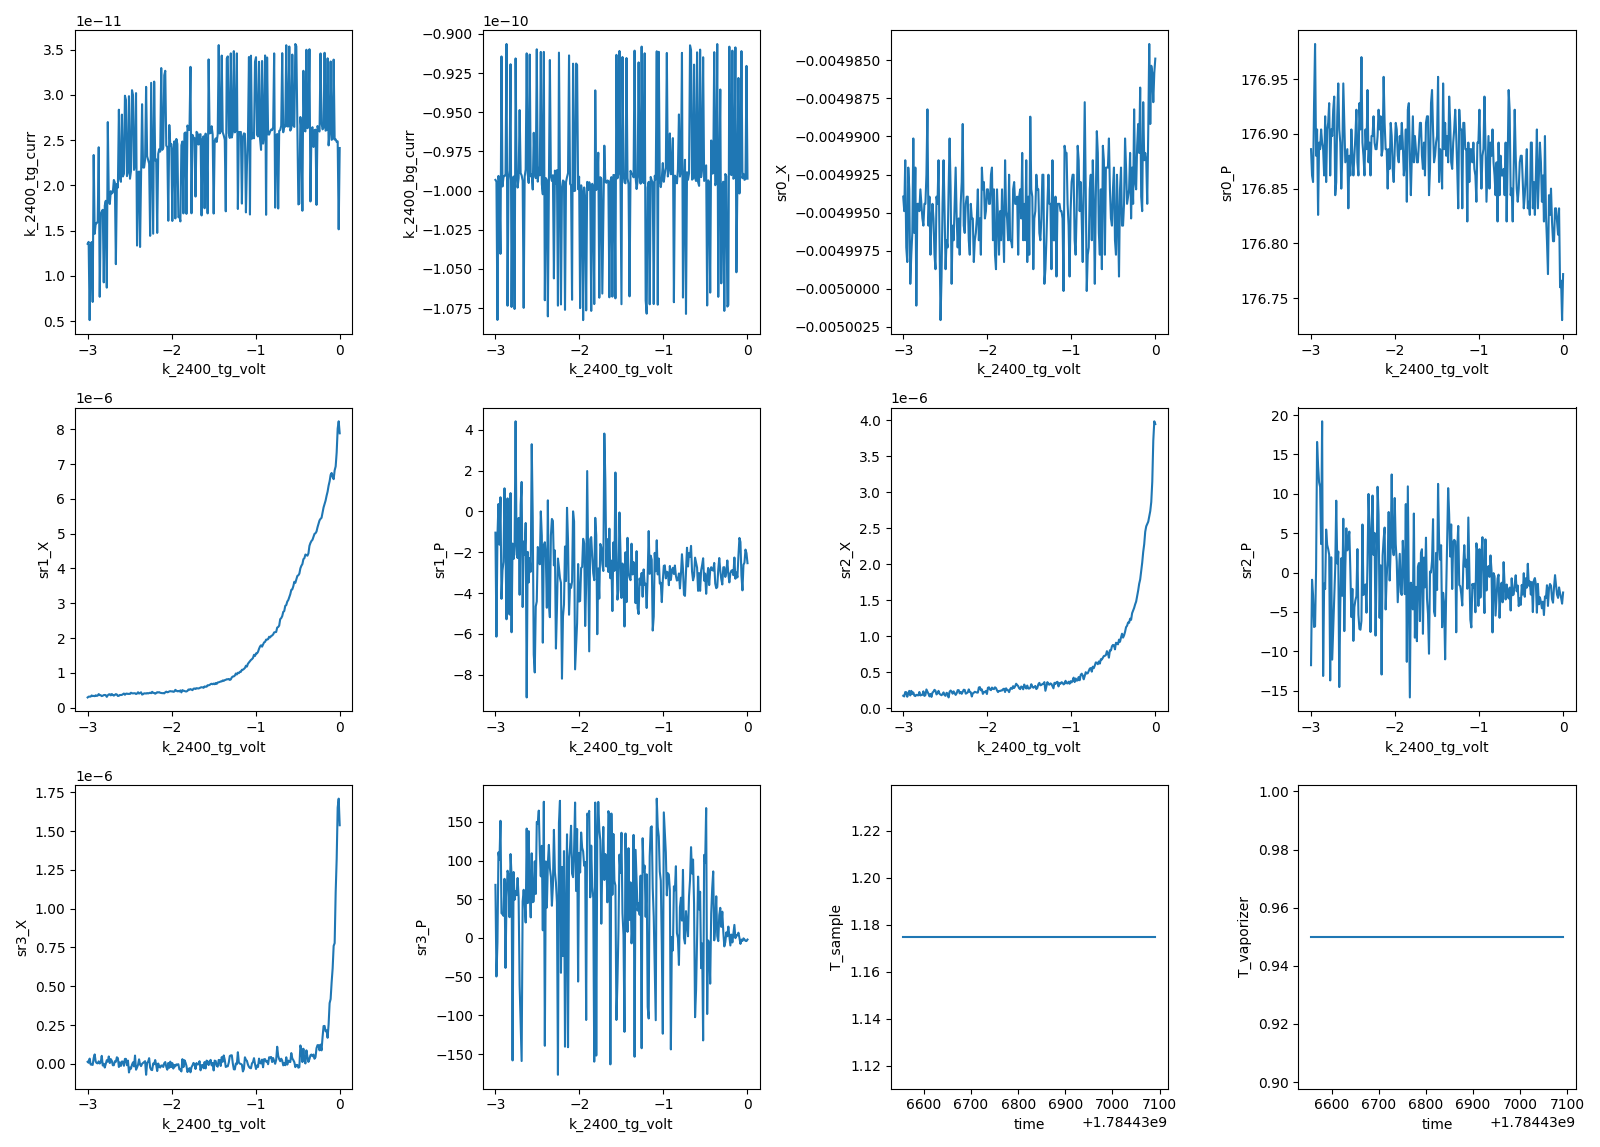

2026-07-18 21:58:12,723 [INFO] Completed in 0h 8m 56s


2026-07-18 21:58:12,723 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260718-QC0426\data\1\data.tsv.gz


2026-07-18 21:58:13,235 [INFO] Ramping k_2400_tg_volt: -3.0 -> 0


leg done: k_2400_tg 0 -> -3 V


2026-07-18 21:58:17,595 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-07-18 21:58:18,119 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-07-18 21:58:18,132 [INFO] Starting sweep with ID 2


2026-07-18 21:58:18,132 [INFO] Minimum duration 0h 4m 11s


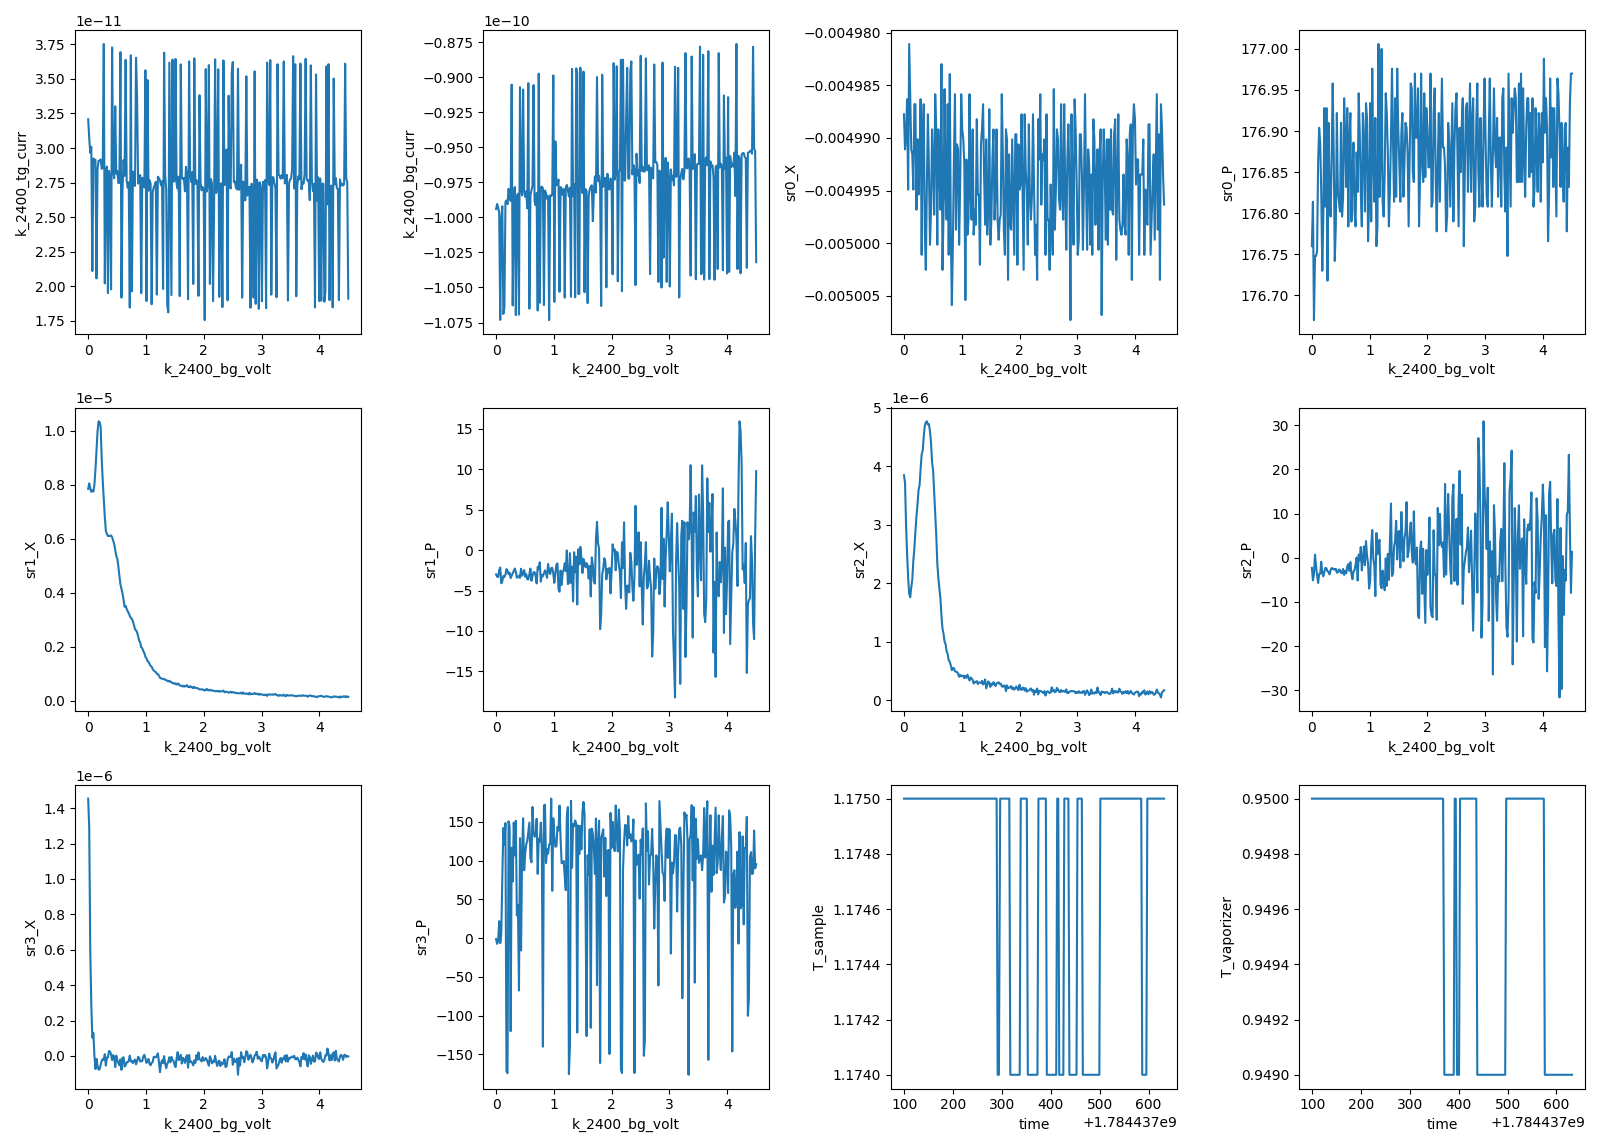

2026-07-18 22:07:13,653 [INFO] Completed in 0h 8m 54s


2026-07-18 22:07:13,654 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260718-QC0426\data\2\data.tsv.gz


2026-07-18 22:07:14,173 [INFO] Ramping k_2400_bg_volt: 4.5 -> 0


leg done: k_2400_bg 0 -> +4.5 V


2026-07-18 22:07:20,328 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-07-18 22:07:20,851 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-07-18 22:07:20,863 [INFO] Starting sweep with ID 3


2026-07-18 22:07:20,865 [INFO] Minimum duration 0h 4m 11s


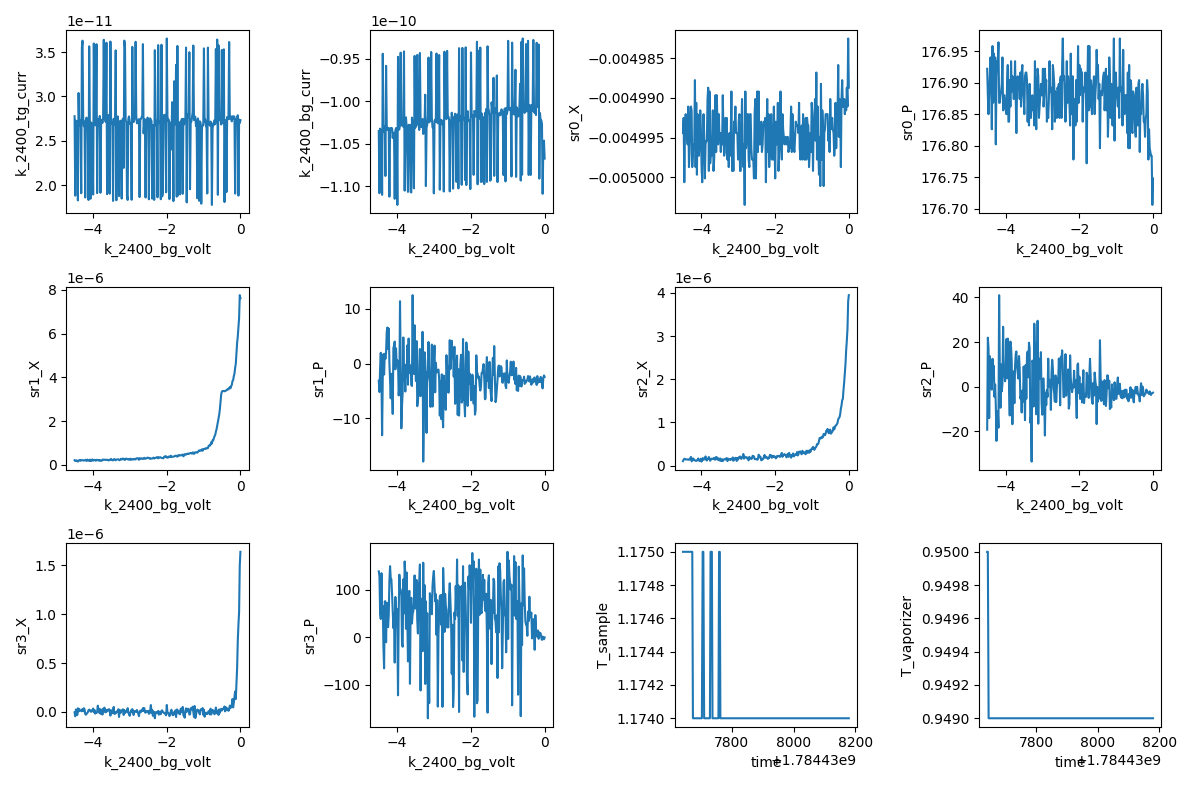

2026-07-18 22:16:21,367 [INFO] Completed in 0h 8m 59s


2026-07-18 22:16:21,367 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260718-QC0426\data\3\data.tsv.gz


2026-07-18 22:16:21,886 [INFO] Ramping k_2400_bg_volt: -4.5 -> 0


leg done: k_2400_bg 0 -> -4.5 V
gate-current-sanity-check: all 4 legs complete; TG/BG parked at 0


In [17]:
# === Gate C — gate-current-sanity-check: every active metal gate, 0 -> each card limit ===
# recipe: device-init/gate-current-sanity-check.md (Si parked: no readback, screened, survey blocklisted)

# --- preconditions (state this cell assumes but does not set) ---
_Ts, _B, _Vsi = T_sample(), magnet.field(), dc205.voltage()
print(f"preconditions: T_sample={_Ts:.3f} K (expect 1.0-1.5), B={_B:+.4f} T (expect ~0), V_si={_Vsi:+.3f} V (expect 0)")
assert 1.0 <= _Ts <= 1.5, f"not at base T: {_Ts:.3f} K"
assert abs(_B) <= 0.02, f"field not at zero: {_B:+.4f} T"
assert abs(_Vsi) <= 0.05, f"Si gate not parked: {_Vsi:+.3f} V"

# --- bring-up record: operator-set lock-in settling state (metadata stores None for these) ---
for _lia in (sr0, sr1, sr2, sr3):
    print(f"{_lia.name}: tau={_lia.time_constant()} s, slope={_lia.filter_slope()} dB/oct, sens(pre)={_lia.sensitivity()}")

# --- drive + sensitivities: device-card starting points (CNP / gate-map scale) ---
sr1.amplitude(0.5)       # 0.5 V / 100 MOhm bias resistor = 5 nA (card)
sr1.sensitivity(2e-5)
sr2.sensitivity(2e-5)
sr3.sensitivity(2e-5)
sr0.sensitivity(1e-2)    # drain: 5 nA x 1e6 V/A = 5 mV

# pA-floor gate-current readback for the legs; the reset cell restores nplci=1
k_2400_tg.nplci(10)
k_2400_bg.nplci(10)

legs = [
    (k_tg, TG_MAX), (k_tg, TG_MIN),   # runs 0, 1
    (k_bg, BG_MAX), (k_bg, BG_MIN),   # runs 2, 3
]
n_pts, leg_delay = 251, 1.0

for gate, v_end in legs:
    meas_config["comments"] = f"gate-current-sanity-check: {gate.name}.volt 0 -> {v_end:+g} V, other metal gate + Si parked at 0"
    s = sweep.AsyncStation(meas_config)
    s.add_comment('gate-current-sanity-check')
    s.add_comment(f'gate: {gate.name}, leg: 0 -> {v_end:+g} V (card limit), n_pts={n_pts}, delay={leg_delay} s, nplci=10, I_bias=5 nA, T=base')
    s.ramp(k_tg.volt, 0)
    s.ramp(k_bg.volt, 0)
    xp = gate.volt
    s.fp(T_sample).fp(T_vaporizer)
    s.fp(k_tg.volt).fp(k_tg.curr)
    s.fp(k_bg.volt).fp(k_bg.curr)
    for _l in (sr0, sr1, sr2, sr3):
        s.fp(_l.X).fp(_l.P)
    s.plot(xp, k_tg.curr)
    s.plot(xp, k_bg.curr)
    for _l in (sr0, sr1, sr2, sr3):
        s.plot(xp, _l.X)
        s.plot(xp, _l.P)
    s.plot('time', T_sample)
    s.plot('time', T_vaporizer)
    try:
        s.sweep(xp, np.linspace(0, v_end, n_pts), delay=leg_delay)
    finally:
        s.ramp(gate.volt, 0)
    print(f"leg done: {gate.name} 0 -> {v_end:+g} V")

print("gate-current-sanity-check: all 4 legs complete; TG/BG parked at 0")


In [18]:
# === Gate C reset — restore standard gate-current nplci ===
# Run ONLY after all four legs read clean from disk (HERA executes post-verification).
k_2400_tg.nplci(1)
k_2400_bg.nplci(1)
print("k_tg.volt validator:", k_2400_tg.volt.vals)
print("k_bg.volt validator:", k_2400_bg.volt.vals)
print("nplci reset to 1 on both Keithleys")


k_tg.volt validator: <Numbers -3.0<=v<=3.0>
k_bg.volt validator: <Numbers -4.5<=v<=4.5>
nplci reset to 1 on both Keithleys


## HERA — Step 1: B = 0 gate map (input to CNP / (n, D) calibration)

Recipes: `measurements/gatemap.md` (axis-aligned first map, raw gate voltages — no calibration assumed) feeding `device-init/cnp-and-dline-calibration.md`; Step 1 of `investigations/trilayer-stacking-fs-count.md`.

**What:** 101 (BG slow, −4.5 → +4.5 V, 90 mV steps) × 101 (TG fast, −3 → +3 V, 60 mV steps) megasweep over the **full validator window** at B = 0, base T, Si = 0. Gate C found the CNP near (0, 0), so this window brackets it with maximal margin; the geometry-prior CNP slope (−c_bg/c_tg ≈ −1.3) exits the TG window at |V_bg| ≳ 2.3 V — those rows will be edge-clipped and excluded from the fit (recipe step 1 guard), while the full BG span still buys the D-range for spotting gap opening and insulating arms.

**Coverage trade (stated):** 101×101 rather than the canonical 201×201 — at this rig's 1.2 s dwell floor (τ = 0.3 s, 24 dB/oct) the dense map costs ~15 h; 60/90 mV steps put ~8–10 points across the ~0.5–1 V-wide CNP ridge seen in runs 0–3, which is sufficient for the smoothed-argmax + polyfit extraction. Price of full density: +11 h; buy it later as a targeted denser map only if fit residuals demand.

**Sensitivity:** sr1/sr2 → 5e-5 (headroom to R ≈ 10 kΩ for a gapped CNP at finite D; runs 0–3 peaked at 2.1 kΩ on-axis), sr3 stays 2e-5 (Hall, ~0 at B = 0). sr0 1e-2. Drive unchanged, 5 nA.

**Price:** 1.25 s/pt (0.25 s NPLC-1 readback + 1.0 s fast_delay; dwell ≥ card 1.2 s floor) → 136 s/row (incl. 7 s flyback + 3 s slow_delay) × 101 rows ≈ **3.9 h nominal, 4–4.5 h realistic** (rig-card 5–10% overrun rule; timing calibrated against runs 0–3 for the NPLC-10 class). Expected done ~03:00.

**Checkpoints:** first rows (leakage / clipping / dead channel — cheapest kill), then periodic digest reads (~hourly): per-row R_max should trace a continuous ridge; abort/adjust if sr1/sr2 rail (fs → 1) over many rows or gate current departs the pA offsets. E1 auto-bucket: in-envelope, inside committed validators.


preconditions: T_sample=1.174 K (expect 1.0-1.5), B=+0.0034 T (expect ~0), V_si=+0.000 V (expect 0), nplci tg/bg=1.0/1.0 (expect 1/1)
2026-07-18 22:20:48,452 [INFO] Ramping k_2400_tg_volt: 0.0 -> -3.0


2026-07-18 22:20:52,345 [INFO] Ramping k_2400_bg_volt: 0.0 -> -4.5


2026-07-18 22:21:08,071 [INFO] Starting megasweep with ID 4


2026-07-18 22:21:08,072 [INFO] Minimum duration 2h 55m 4s


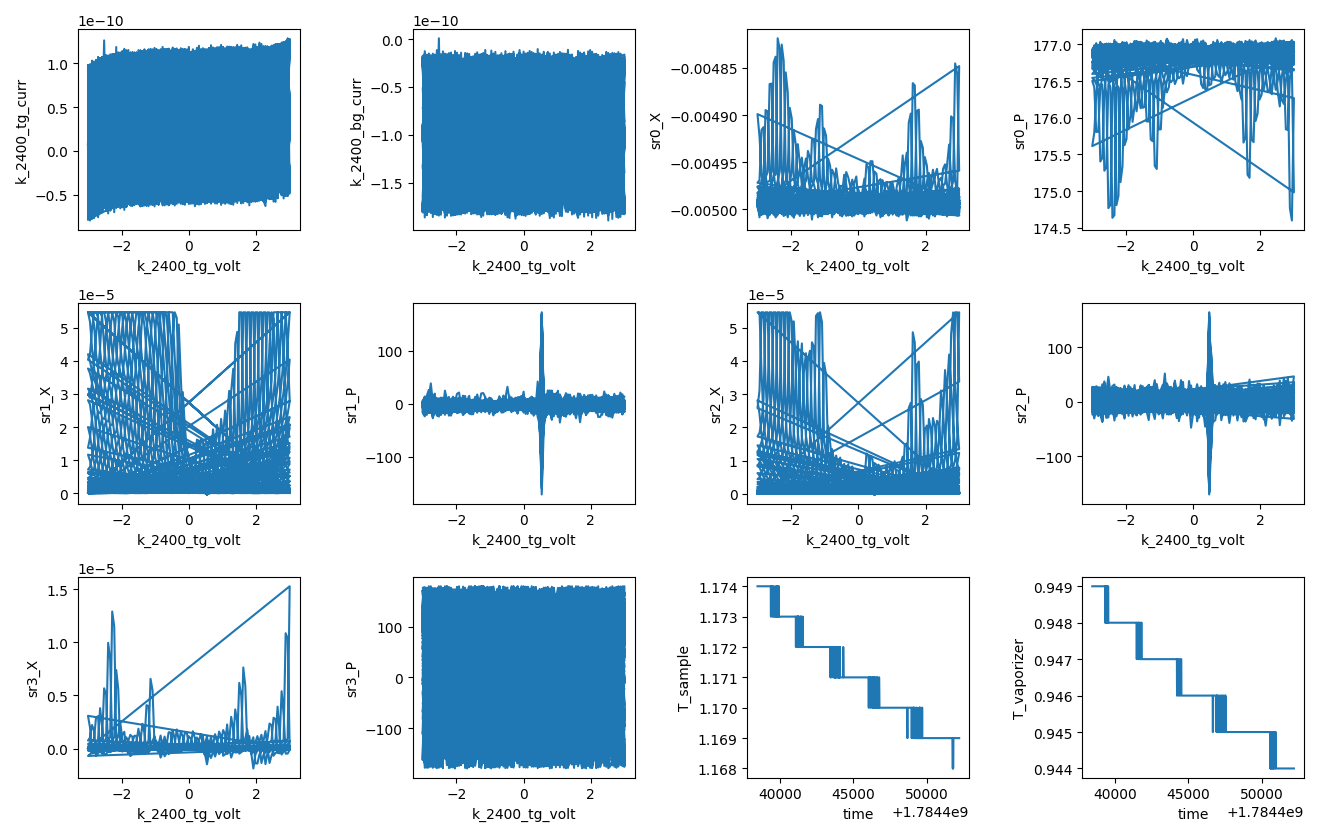

2026-07-19 02:09:49,308 [INFO] Completed in 3h 48m 40s


2026-07-19 02:09:49,308 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260718-QC0426\data\4\data.tsv.gz


2026-07-19 02:09:49,379 [INFO] Ramping k_2400_tg_volt: 3.0 -> 0


2026-07-19 02:09:53,211 [INFO] Ramping k_2400_bg_volt: 4.5 -> 0


gatemap complete; gates parked at 0


In [19]:
# === Step 1 — B=0 gate map: TG fast [-3,+3]x101, BG slow [-4.5,+4.5]x101 ===
# recipes: measurements/gatemap.md -> device-init/cnp-and-dline-calibration.md
# (trilayer-stacking-fs-count Step 1)

# --- preconditions (state this cell assumes but does not set) ---
_Ts, _B, _Vsi = T_sample(), magnet.field(), dc205.voltage()
_np_tg, _np_bg = k_2400_tg.nplci(), k_2400_bg.nplci()
print(f"preconditions: T_sample={_Ts:.3f} K (expect 1.0-1.5), B={_B:+.4f} T (expect ~0), "
      f"V_si={_Vsi:+.3f} V (expect 0), nplci tg/bg={_np_tg}/{_np_bg} (expect 1/1)")
assert 1.0 <= _Ts <= 1.5, f"not at base T: {_Ts:.3f} K"
assert abs(_B) <= 0.02, f"field not at zero: {_B:+.4f} T"
assert abs(_Vsi) <= 0.05, f"Si gate not parked: {_Vsi:+.3f} V"
assert _np_tg == 1 and _np_bg == 1, "nplci not reset to 1 — run the Gate C reset cell"

# --- sensitivities for the map (stated in the proposal md) ---
sr1.sensitivity(5e-5)   # headroom to R ~ 10 kOhm (gapped CNP at finite D)
sr2.sensitivity(5e-5)
sr3.sensitivity(2e-5)   # Hall, ~0 at B=0
sr0.sensitivity(1e-2)

tg_fast = np.linspace(-3.0, 3.0, 101)    # 60 mV steps
bg_slow = np.linspace(-4.5, 4.5, 101)    # 90 mV steps

meas_config["comments"] = ("gatemap: B=0, base T, Si=0; TG fast [-3,+3]x101, BG slow [-4.5,+4.5]x101, "
                           "fast_delay=1, slow_delay=3, I_bias=5 nA, sens sr1/sr2=5e-5 sr3=2e-5")
s = sweep.AsyncStation(meas_config)
s.add_comment('gatemap')
s.add_comment('first map of cooldown: full validator window, raw gate voltages (no (n,D) cal yet); '
              'input to cnp-and-dline-calibration; CNP expected near (0,0) from runs 0-3')

s.ramp(k_tg.volt, tg_fast[0])
s.ramp(k_bg.volt, bg_slow[0])
interruptible_sleep(10)

xp = k_tg.volt
s.fp(T_sample).fp(T_vaporizer)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
for _l in (sr0, sr1, sr2, sr3):
    s.fp(_l.X).fp(_l.P)
s.plot(xp, k_tg.curr)
s.plot(xp, k_bg.curr)
for _l in (sr0, sr1, sr2, sr3):
    s.plot(xp, _l.X)
    s.plot(xp, _l.P)
s.plot('time', T_sample)
s.plot('time', T_vaporizer)

try:
    s.megasweep(k_bg.volt, bg_slow, k_tg.volt, tg_fast,
                slow_delay=3, fast_delay=1)
finally:
    s.ramp(k_tg.volt, 0)
    s.ramp(k_bg.volt, 0)
print("gatemap complete; gates parked at 0")


## HERA — Step 3: SdH spot checks at n = ±6×10¹² cm⁻², D = 0

Recipes: `measurements/sdh-spot-check.md` (mechanics per `field-sweep-1d`); Step 3 of `trilayer-stacking-fs-count`. Both density signs get a spot check (no side prior); electron side first, hole side second on the return traverse (never re-traverse — the hole cell sweeps 8 → 0.5 T).

**Design (from the Step-1/2 numbers on the page above and in ana):**
- Operating points on the calibrated D = 0 line: **electron (V_tg, V_bg) = (+2.849, +2.216)**, **hole (−2.797, −2.176)** — |n| = 6×10¹² cm⁻² pushes the periods without leaving the TG-limited window (realized max 6.3). **F_L = 62.0 T**.
- **Blocking rate-limited magnet → uniform-B grid**, Nyquist held at the low edge (recipe step 1b): two segments — **0.5→1.0 T at ΔB = 2.0 mT** (Nyquist for F_L at B = 0.5) and **1.0→8.0 T at ΔB = 5.4 mT** (1.5× Nyquist margin at 1.0 T; oversampling in 1/B grows as B²). ~1550 pts. The 0.5 T floor sits below the expected onset (~1.5–3 T at this rig's 8 K electron temperature) so the onset is read directly; if oscillations were somehow alive below 0.5 T the onset comes back censored and we revisit.
- **δF forecast**: onset 2 T → usable record 0.375 /T → δF ≈ 2.7 T. An ABA pair (f_ML + f_BL = 62) separates cleanly unless f_ML ≲ 5 T; the fan's n-tracking refines whatever this leaves merged.
- **Settling**: dwell per point = magnet `settle_s` (3 s ≈ 10τ at τ = 0.3 s, 24 dB/oct — at the recipe's weak-tone floor, not bent) + ~0.25 s read; `delay=0` adds nothing. Per-point spacing ≈ ramp (0.9–2.4 s) + 3.25 s.
- **Sensitivities** (card starting points, tuned to run-4 corner values and Hall arithmetic — stated): bias 2 V → 20 nA; sr1 2e-6 (R ~30 Ω → fs 0.3); **sr2 1e-6** (card 5e-7 would clip: 25–35 Ω × 20 nA ≈ 0.6 µV); **sr3 5e-5** (R_xy(8 T) ≈ 830 Ω → 17 µV; card 5e-6 clips 3×); **sr0 5e-2** (20 nA × 1e6 = 20 mV; card 1e-2 clips 2×).

**Price per spot check:** ~1550 pts × ~5.3 s + initial ramps ≈ **2.3 h nominal, 2.4–2.6 h realistic**; two checks ≈ **5 h**. Ends at 0.5 T (fan-ready). Checkpoints: first rows (clipping/leakage/MR shape), then periodic digest reads; the electron-side FFT is read **before** the hole cell runs — its result can adjust the hole design.

E1 auto-bucket: field moves within the 8 T cap, gates inside validators, no T change.


In [20]:
# === Session calibration commit (run 4) — supersedes the geometry-prior `cal` from the setup slot ===
# ratio data-calibrated (CNP slope), scale anchored on c_tg stack prior; see ana + device card.
from sharpelab_nb.gates import calc_gate_voltages as _cgv

CAL_SLOPE = -1.2852          # combined sr1/sr2 CNP slope, run 4
CAL_B = +0.0513              # V_tg intercept at V_bg = 0
c_tg_cal = stack_capacitance([(15.6, 3)])       # F/m^2, geometry-prior anchor
c_bg_cal = -CAL_SLOPE * c_tg_cal                 # ratio-calibrated
n_off_disp = -calc_nD(CAL_B, 0, c_tg_cal, c_bg_cal)[0]   # 1e12 cm^-2 (sharpelab display units)
cal = GateCalibration(c_tg=c_tg_cal, c_bg=c_bg_cal, n_offset=n_off_disp * 1e16, D_offset=0.0)  # SI

def d0_point(n_e12):
    """(V_tg, V_bg) on the calibrated D=0 line at n [1e12 cm^-2]."""
    return _cgv(n_e12, 0.0, c_tg_cal, c_bg_cal, n_offset=n_off_disp)

print(f"cal committed: c_bg/c_tg = {c_bg_cal/c_tg_cal:.4f}, n_offset = {n_off_disp:+.4f} e12 cm^-2")
print(f"D=0 points: n=+6 -> {d0_point(6.0)}, n=-6 -> {d0_point(-6.0)}")


NameError: name 'stack_capacitance' is not defined

preconditions: T_sample=1.169 K (expect 1.0-1.5), B=+0.0034 T (expect <0.6, ramping up), V_si=+0.000 V (expect 0), settle_s=3.0 (expect 3 s), nplci=1.0/1.0 (expect 1/1)
target: (Vtg, Vbg) = (+2.848, +2.216); 1547 field points
2026-07-19 02:19:09,783 [INFO] Ramping k_2400_tg_volt: 0.0 -> 2.8484899960375416


2026-07-19 02:19:13,431 [INFO] Ramping k_2400_bg_volt: 0.0 -> 2.21637877064857


2026-07-19 02:19:26,207 [INFO] Ramping magnet_field: 0.003396794520547945 -> 0.5


2026-07-19 02:23:08,320 [INFO] Starting sweep with ID 5


2026-07-19 02:23:08,321 [INFO] Minimum duration 0h 0m 0s


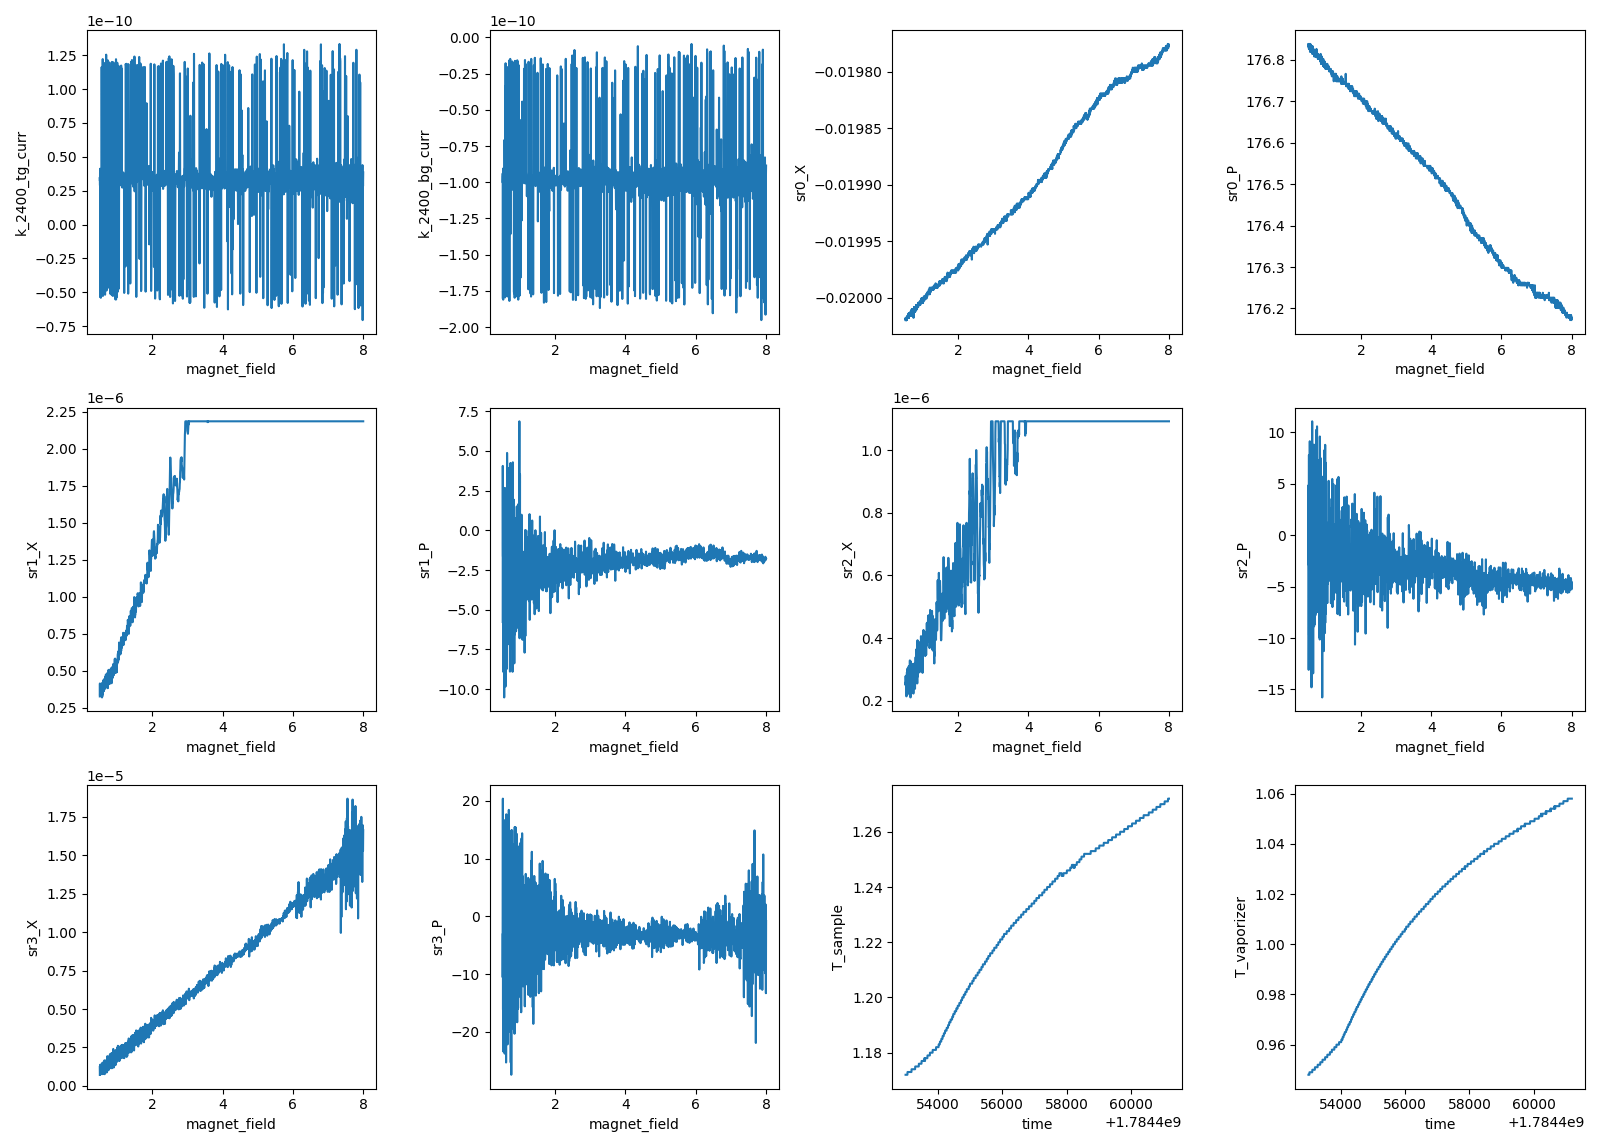

2026-07-19 04:39:49,351 [INFO] Completed in 2h 16m 40s


2026-07-19 04:39:49,352 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260718-QC0426\data\5\data.tsv.gz


electron spot check done; field holds at 8 T, gates at the electron point


In [22]:
# === Step 3a — SdH spot check, ELECTRON side: n = +6e12 cm^-2, D = 0, B 0.5 -> 8 T ===
# recipe: measurements/sdh-spot-check.md (uniform-B, blocking magnet)

# --- preconditions ---
_Ts, _B, _Vsi = T_sample(), magnet.field(), dc205.voltage()
print(f"preconditions: T_sample={_Ts:.3f} K (expect 1.0-1.5), B={_B:+.4f} T (expect <0.6, ramping up), "
      f"V_si={_Vsi:+.3f} V (expect 0), settle_s={getattr(magnet, 'settle_s', '?')} (expect 3 s), "
      f"nplci={k_2400_tg.nplci()}/{k_2400_bg.nplci()} (expect 1/1)")
assert 1.0 <= _Ts <= 1.5, f"not at base T: {_Ts:.3f} K"
assert abs(_B) <= 0.6, f"field too high to start the up-sweep: {_B:+.4f} T"
assert abs(_Vsi) <= 0.05, f"Si gate not parked: {_Vsi:+.3f} V"

# --- drive + sensitivities (high-|n| metallic; card starting points tuned — see md) ---
sr1.amplitude(2.0)      # 2 V / 100 MOhm = 20 nA
sr1.sensitivity(2e-6)
sr2.sensitivity(1e-6)
sr3.sensitivity(5e-5)   # R_xy(8 T) ~ 830 Ohm -> 17 uV
sr0.sensitivity(5e-2)   # 20 nA x 1e6 = 20 mV

# --- uniform-B grid, Nyquist at the low edge (F_L = 62 T) ---
B_vec = np.concatenate([np.arange(0.5, 1.0, 0.002),          # onset segment
                        np.arange(1.0, 8.0 + 1e-9, 0.0054)])  # main segment
vtg_pt, vbg_pt = d0_point(+6.0)
print(f"target: (Vtg, Vbg) = ({vtg_pt:+.3f}, {vbg_pt:+.3f}); {len(B_vec)} field points")

meas_config["comments"] = (f"sdh-spot-check: electron n=+6e12 cm^-2 D=0 (Vtg={vtg_pt:+.3f}, Vbg={vbg_pt:+.3f}), "
                           "B 0.5->8 T uniform-B (2.0 mT to 1 T, 5.4 mT above), I_bias=20 nA, F_L=62 T")
s = sweep.AsyncStation(meas_config)
s.add_comment('sdh-spot-check')
s.add_comment('electron side; grid: Nyquist at low edge per segment; dwell = settle_s 3 s (=10 tau); '
              'cal: run-4 CNP calibration (see device card)')

s.ramp(k_tg.volt, vtg_pt)
s.ramp(k_bg.volt, vbg_pt)
interruptible_sleep(10)
s.ramp(magnet.field, B_vec[0])   # blocking ramp to the floor

xp = magnet.field
s.fp(T_sample).fp(T_vaporizer)
s.fp(magnet.field)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
for _l in (sr0, sr1, sr2, sr3):
    s.fp(_l.X).fp(_l.P)
s.plot(xp, k_tg.curr)
s.plot(xp, k_bg.curr)
for _l in (sr0, sr1, sr2, sr3):
    s.plot(xp, _l.X)
    s.plot(xp, _l.P)
s.plot('time', T_sample)
s.plot('time', T_vaporizer)

s.sweep(magnet.field, B_vec, delay=0)   # dwell = magnet settle_s + readback
print("electron spot check done; field holds at 8 T, gates at the electron point")


In [ ]:
# === Step 3b — SdH spot check, HOLE side: n = -6e12 cm^-2, D = 0, B 8 -> 0.5 T (return traverse) ===
# recipe: measurements/sdh-spot-check.md; run AFTER the electron-side read.

# --- preconditions ---
_Ts, _B, _Vsi = T_sample(), magnet.field(), dc205.voltage()
print(f"preconditions: T_sample={_Ts:.3f} K (expect 1.0-1.5), B={_B:+.4f} T (expect ~8, sweeping down), "
      f"V_si={_Vsi:+.3f} V (expect 0)")
assert 1.0 <= _Ts <= 1.5, f"not at base T: {_Ts:.3f} K"
assert _B > 7.5, f"field not at the top of the window: {_B:+.4f} T (this cell sweeps down)"
assert abs(_Vsi) <= 0.05, f"Si gate not parked: {_Vsi:+.3f} V"

# sensitivities unchanged from 3a (same |n|, symmetric R); drive stays 20 nA
B_vec_dn = np.concatenate([np.arange(0.5, 1.0, 0.002),
                           np.arange(1.0, 8.0 + 1e-9, 0.0054)])[::-1]
vtg_pt, vbg_pt = d0_point(-6.0)
print(f"target: (Vtg, Vbg) = ({vtg_pt:+.3f}, {vbg_pt:+.3f}); {len(B_vec_dn)} field points")

meas_config["comments"] = (f"sdh-spot-check: hole n=-6e12 cm^-2 D=0 (Vtg={vtg_pt:+.3f}, Vbg={vbg_pt:+.3f}), "
                           "B 8->0.5 T uniform-B (5.4 mT to 1 T, 2.0 mT below), I_bias=20 nA, F_L=62 T")
s = sweep.AsyncStation(meas_config)
s.add_comment('sdh-spot-check')
s.add_comment('hole side; descending traverse (never re-traverse); grid/dwell as electron cell; '
              'cal: run-4 CNP calibration')

s.ramp(k_tg.volt, vtg_pt)   # gate move at 8 T along validated ranges
s.ramp(k_bg.volt, vbg_pt)
interruptible_sleep(10)

xp = magnet.field
s.fp(T_sample).fp(T_vaporizer)
s.fp(magnet.field)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
for _l in (sr0, sr1, sr2, sr3):
    s.fp(_l.X).fp(_l.P)
s.plot(xp, k_tg.curr)
s.plot(xp, k_bg.curr)
for _l in (sr0, sr1, sr2, sr3):
    s.plot(xp, _l.X)
    s.plot(xp, _l.P)
s.plot('time', T_sample)
s.plot('time', T_vaporizer)

s.sweep(magnet.field, B_vec_dn, delay=0)
print("hole spot check done; field holds at 0.5 T, gates at the hole point")


## HERA — commit-cell fix: previous cell NameError (stack_capacitance not in kernel namespace — cell 21 used GateCalibration.from_thicknesses only). Same numbers, imports added.

In [21]:
# === Session calibration commit v2 (run 4) — fixes the missing sharpelab_nb.gates imports ===
from sharpelab_nb.gates import stack_capacitance, calc_nD, calc_gate_voltages as _cgv

CAL_SLOPE = -1.2852          # combined sr1/sr2 CNP slope, run 4
CAL_B = +0.0513              # V_tg intercept at V_bg = 0
c_tg_cal = stack_capacitance([(15.6, 3)])       # F/m^2, geometry-prior anchor
c_bg_cal = -CAL_SLOPE * c_tg_cal                 # ratio-calibrated
n_off_disp = -calc_nD(CAL_B, 0, c_tg_cal, c_bg_cal)[0]   # 1e12 cm^-2 (sharpelab display units)
cal = GateCalibration(c_tg=c_tg_cal, c_bg=c_bg_cal, n_offset=n_off_disp * 1e16, D_offset=0.0)  # SI

def d0_point(n_e12):
    """(V_tg, V_bg) on the calibrated D=0 line at n [1e12 cm^-2]."""
    return _cgv(n_e12, 0.0, c_tg_cal, c_bg_cal, n_offset=n_off_disp)

print(f"cal committed: c_bg/c_tg = {c_bg_cal/c_tg_cal:.4f}, n_offset = {n_off_disp:+.4f} e12 cm^-2")
print(f"D=0 points: n=+6 -> {d0_point(6.0)}, n=-6 -> {d0_point(-6.0)}")


cal committed: c_bg/c_tg = 1.2852, n_offset = -0.0545 e12 cm^-2
D=0 points: n=+6 -> (2.8484899960375416, 2.21637877064857), n=-6 -> (-2.797189996037541, -2.1764628042620147)


## HERA — Step 3 redo: unclipped SdH records (runs 6–8); hole cell above superseded

Run 5's sr1/sr2 clipped above ~2.4 T (sensitivities sized from B = 0 resistance, MR growth unbudgeted — my miss, caught at the completion checkpoint; full read in ana). The held hole cell (0b8ef9ac, "Step 3b") is **superseded — do not run** (wrong sensitivities, wrong traverse direction after the redo). Replacement plan, magnet-discipline-ordered (magnet sits at 8 T):

1. **Run 6 — electron re-acquire, 8 → 2.0 T**, 5.4 mT uniform-B, sens sr1 1e-5 / sr2 5e-6 (~1.4× above the linear-MR extrapolation R(8 T) ≈ 360/180 Ω). Down-sweep puts the highest-R points first → a wrong sensitivity guess dies at the first-rows checkpoint, minutes in. 0.5 T overlap with run 5's clean window gives the stitch + grid-change check. ~1.7 h.
2. **Run 7 — hole onset segment, 2.0 → 0.5 T** at 2.0 mT (Nyquist at 0.5 T), gates moved to the hole point (−2.797, −2.176) at 2 T, sens sr1 5e-6 / sr2 2e-6. Reads the hole-side onset directly. ~51 min.
3. **Run 8 — hole main record, 0.5 → 8 T** (bare ramp to 1.0 T, points 1.0 → 8.0 at 5.4 mT), sens as run 6. Ends at 8 T, fan-ready. ~2.0 h.

Combined ~4.7 h; electron analysis (runs 5+6 stitched) proceeds while runs 7–8 acquire. Net cost of the clip ≈ +2 h vs the original plan — bought back partly by run 5's fine low-B record, which stands as the onset measurement. E1 auto-bucket throughout.


preconditions: T_sample=1.272 K (expect 1.0-1.5), B=+8.0018 T (expect ~8), gates (+2.849, +2.216) (expect electron point +2.848/+2.216)
2026-07-19 04:45:01,387 [INFO] Starting sweep with ID 6


2026-07-19 04:45:01,388 [INFO] Minimum duration 0h 0m 0s


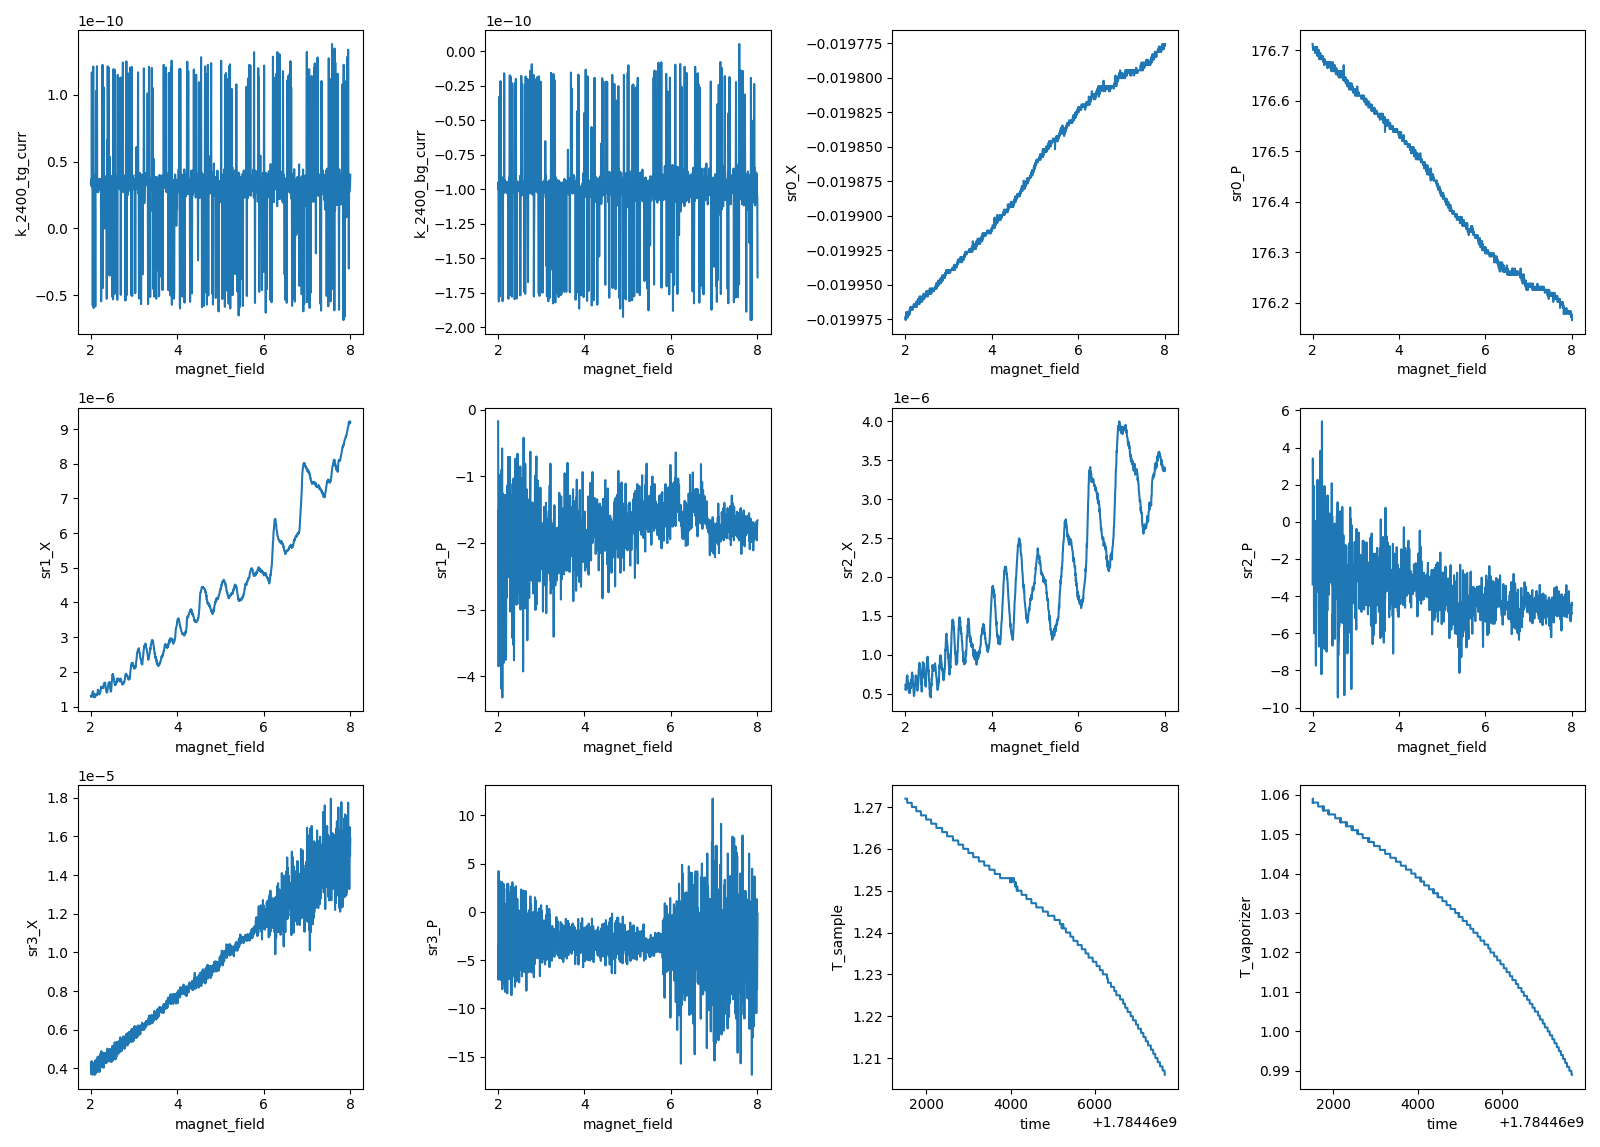

2026-07-19 06:27:41,400 [INFO] Completed in 1h 42m 39s


2026-07-19 06:27:41,401 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260718-QC0426\data\6\data.tsv.gz


run 6 done; field at 2 T, gates at electron point


In [23]:
# === Step 3 redo, run 6 — electron re-acquire: n = +6e12, D = 0, B 8 -> 2 T, unclipped sens ===
_Ts, _B = T_sample(), magnet.field()
print(f"preconditions: T_sample={_Ts:.3f} K (expect 1.0-1.5), B={_B:+.4f} T (expect ~8), "
      f"gates ({k_tg.volt():+.3f}, {k_bg.volt():+.3f}) (expect electron point +2.848/+2.216)")
assert 1.0 <= _Ts <= 1.5, f"not at base T: {_Ts:.3f} K"
assert _B > 7.5, f"field not at 8 T: {_B:+.4f}"
assert abs(k_tg.volt() - 2.8485) < 0.01 and abs(k_bg.volt() - 2.2164) < 0.01, "gates not at the electron point"

sr1.sensitivity(1e-5)   # ceiling 500 Ohm (extrapolated R(8T) ~ 360)
sr2.sensitivity(5e-6)   # ceiling 250 Ohm (extrapolated ~ 180)
# sr3 5e-5, sr0 5e-2 unchanged (unclipped in run 5)

B_dn = np.arange(8.0, 2.0 - 1e-9, -0.0054)
meas_config["comments"] = ("sdh-spot-check: electron n=+6e12 D=0 REDO, B 8->2 T uniform-B 5.4 mT, "
                           "sens sr1=1e-5 sr2=5e-6 (run 5 clipped >2.4 T), I_bias=20 nA")
s = sweep.AsyncStation(meas_config)
s.add_comment('sdh-spot-check')
s.add_comment('electron redo, down-traverse; overlap 2.0-2.4 T with run 5 usable window for stitch/grid-change check')

xp = magnet.field
s.fp(T_sample).fp(T_vaporizer)
s.fp(magnet.field)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
for _l in (sr0, sr1, sr2, sr3):
    s.fp(_l.X).fp(_l.P)
s.plot(xp, k_tg.curr)
s.plot(xp, k_bg.curr)
for _l in (sr0, sr1, sr2, sr3):
    s.plot(xp, _l.X)
    s.plot(xp, _l.P)
s.plot('time', T_sample)
s.plot('time', T_vaporizer)

s.sweep(magnet.field, B_dn, delay=0)
print("run 6 done; field at 2 T, gates at electron point")


preconditions: T_sample=1.206 K, B=+2.0040 T (expect ~2)
2026-07-19 06:28:07,205 [INFO] Ramping k_2400_tg_volt: 2.8485 -> -2.797189996037541


2026-07-19 06:28:14,429 [INFO] Ramping k_2400_bg_volt: 2.2165 -> -2.1764628042620147


2026-07-19 06:28:29,987 [INFO] Starting sweep with ID 7


2026-07-19 06:28:29,988 [INFO] Minimum duration 0h 0m 0s


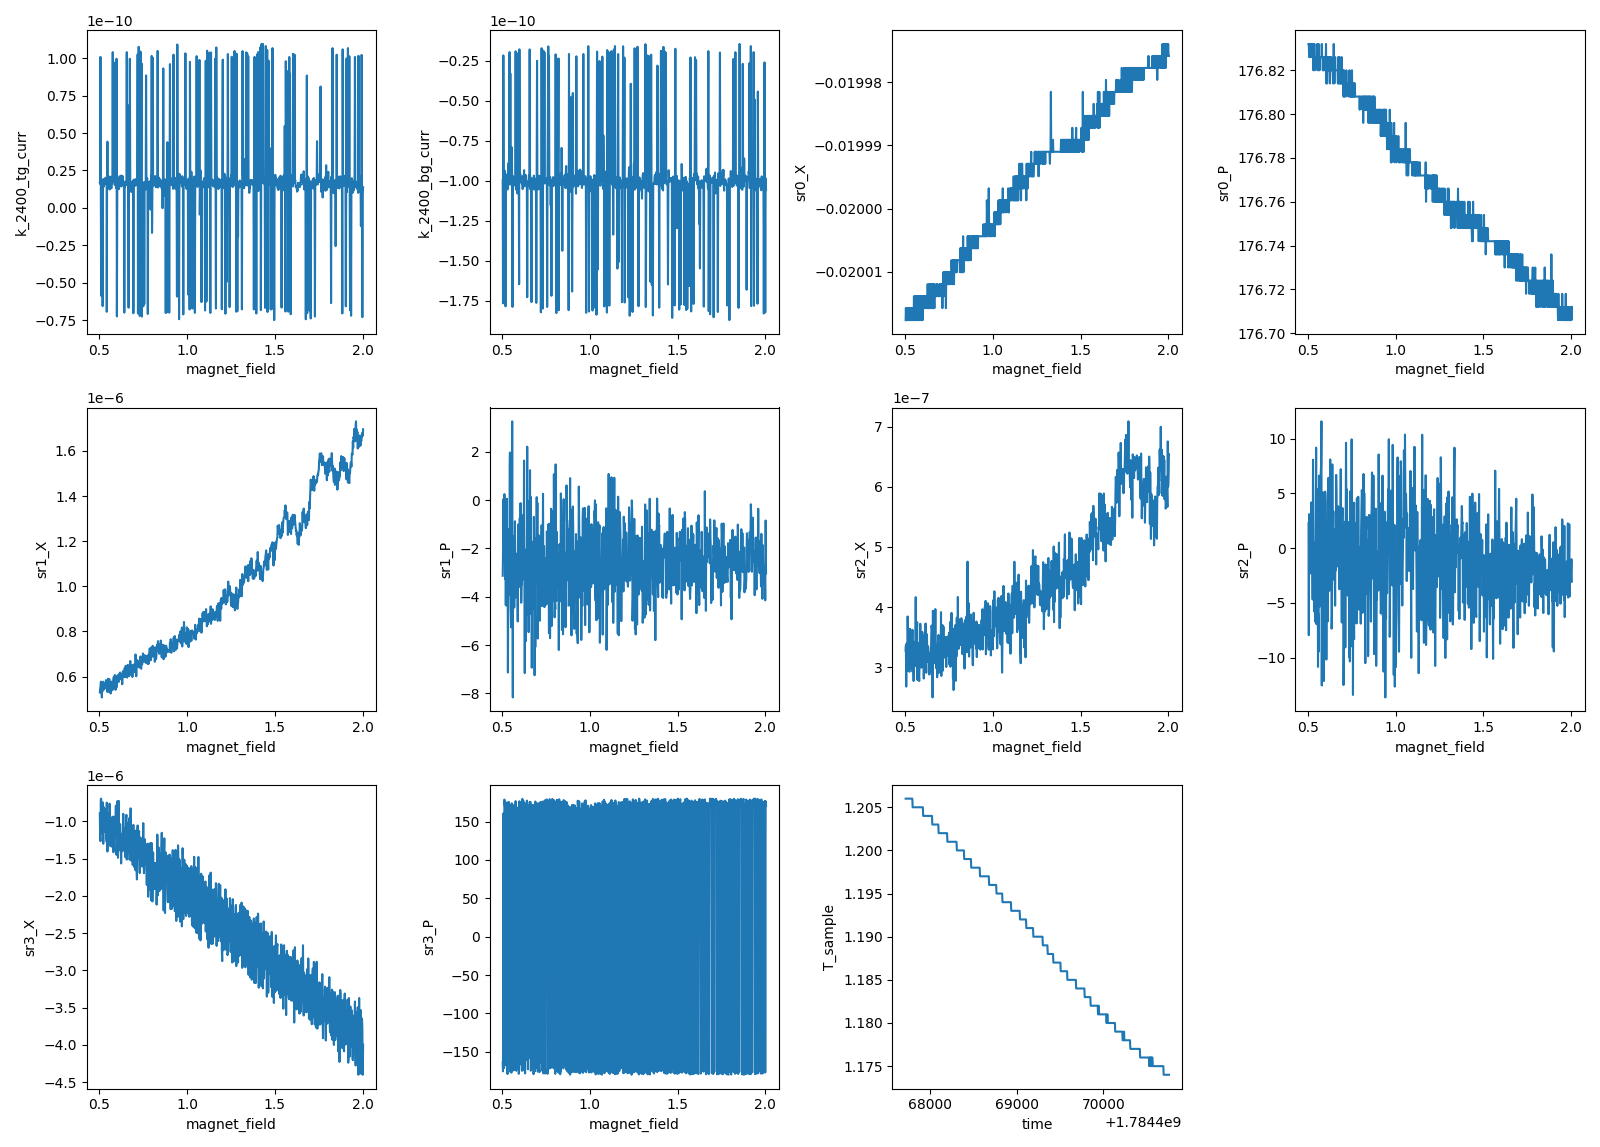

2026-07-19 07:19:20,682 [INFO] Completed in 0h 50m 49s


2026-07-19 07:19:20,683 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260718-QC0426\data\7\data.tsv.gz


run 7 done; field at 0.5 T, gates at hole point


In [24]:
# === Step 3 redo, run 7 — hole onset segment: n = -6e12, D = 0, B 2 -> 0.5 T fine ===
_Ts, _B = T_sample(), magnet.field()
print(f"preconditions: T_sample={_Ts:.3f} K, B={_B:+.4f} T (expect ~2)")
assert 1.0 <= _Ts <= 1.5, f"not at base T: {_Ts:.3f} K"
assert 1.8 < _B < 2.3, f"field not at 2 T: {_B:+.4f}"

vtg_pt, vbg_pt = d0_point(-6.0)
sr1.sensitivity(5e-6)   # ceiling 250 Ohm; hole R(2T) ~ 100 by electron analogy
sr2.sensitivity(2e-6)   # ceiling 100 Ohm

B_dn = np.arange(2.0, 0.5 - 1e-9, -0.002)
meas_config["comments"] = (f"sdh-spot-check: hole n=-6e12 D=0 onset segment (Vtg={vtg_pt:+.3f}, Vbg={vbg_pt:+.3f}), "
                           "B 2->0.5 T uniform-B 2.0 mT (Nyquist at 0.5 T), sens sr1=5e-6 sr2=2e-6, I_bias=20 nA")
s = sweep.AsyncStation(meas_config)
s.add_comment('sdh-spot-check')
s.add_comment('hole side onset segment; gates moved at 2 T; main record follows as run 8 (0.5->8 T)')

s.ramp(k_tg.volt, vtg_pt)
s.ramp(k_bg.volt, vbg_pt)
interruptible_sleep(10)

xp = magnet.field
s.fp(T_sample).fp(T_vaporizer)
s.fp(magnet.field)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
for _l in (sr0, sr1, sr2, sr3):
    s.fp(_l.X).fp(_l.P)
s.plot(xp, k_tg.curr)
s.plot(xp, k_bg.curr)
for _l in (sr0, sr1, sr2, sr3):
    s.plot(xp, _l.X)
    s.plot(xp, _l.P)
s.plot('time', T_sample)

s.sweep(magnet.field, B_dn, delay=0)
print("run 7 done; field at 0.5 T, gates at hole point")


preconditions: T_sample=1.174 K, B=+0.5034 T (expect ~0.5), gates (-2.797, -2.176) (expect hole point -2.797/-2.176)
2026-07-19 07:19:49,218 [INFO] Ramping magnet_field: 0.5034259315068493 -> 1.0


2026-07-19 07:23:30,605 [INFO] Starting sweep with ID 8


2026-07-19 07:23:30,606 [INFO] Minimum duration 0h 0m 0s


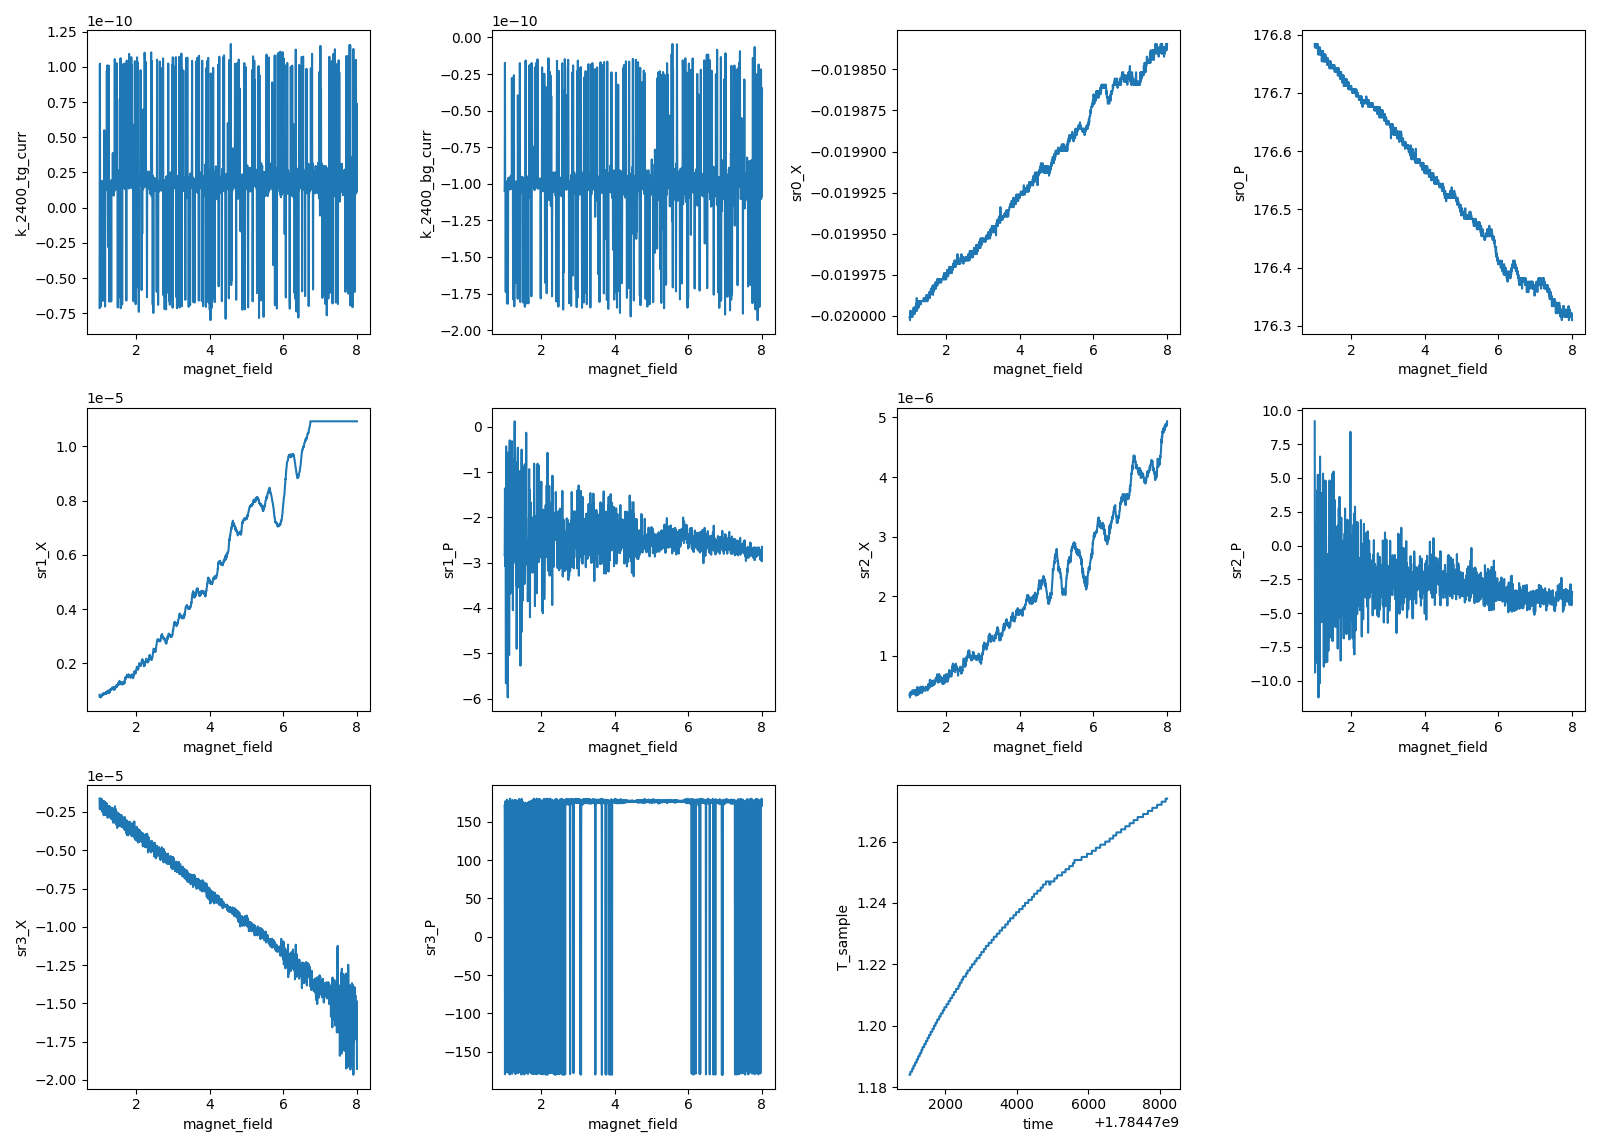

2026-07-19 09:23:17,217 [INFO] Completed in 1h 59m 45s


2026-07-19 09:23:17,218 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260718-QC0426\data\8\data.tsv.gz


run 8 done; field at 8 T, gates at hole point


In [25]:
# === Step 3 redo, run 8 — hole main record: n = -6e12, D = 0, B 0.5 -> 8 T ===
_Ts, _B = T_sample(), magnet.field()
print(f"preconditions: T_sample={_Ts:.3f} K, B={_B:+.4f} T (expect ~0.5), "
      f"gates ({k_tg.volt():+.3f}, {k_bg.volt():+.3f}) (expect hole point -2.797/-2.176)")
assert 1.0 <= _Ts <= 1.5, f"not at base T: {_Ts:.3f} K"
assert 0.4 < _B < 0.7, f"field not at 0.5 T: {_B:+.4f}"
assert abs(k_tg.volt() + 2.7972) < 0.01 and abs(k_bg.volt() + 2.1765) < 0.01, "gates not at the hole point"

sr1.sensitivity(1e-5)   # ceiling 500 Ohm (as run 6)
sr2.sensitivity(5e-6)   # ceiling 250 Ohm

B_up = np.arange(1.0, 8.0 + 1e-9, 0.0054)
meas_config["comments"] = ("sdh-spot-check: hole n=-6e12 D=0 main record, B 1->8 T uniform-B 5.4 mT "
                           "(onset segment = run 7), sens sr1=1e-5 sr2=5e-6, I_bias=20 nA")
s = sweep.AsyncStation(meas_config)
s.add_comment('sdh-spot-check')
s.add_comment('hole side main record; bare ramp 0.5->1.0 T then points; ends at 8 T (fan-ready)')

s.ramp(magnet.field, B_up[0])

xp = magnet.field
s.fp(T_sample).fp(T_vaporizer)
s.fp(magnet.field)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
for _l in (sr0, sr1, sr2, sr3):
    s.fp(_l.X).fp(_l.P)
s.plot(xp, k_tg.curr)
s.plot(xp, k_bg.curr)
for _l in (sr0, sr1, sr2, sr3):
    s.plot(xp, _l.X)
    s.plot(xp, _l.P)
s.plot('time', T_sample)

s.sweep(magnet.field, B_up, delay=0)
print("run 8 done; field at 8 T, gates at hole point")


## HERA — Step 4: D = 0 Landau fan, electron side (per-column SdH-FFT fan)

Recipes: `measurements/landau-fan.md` + `landau-fan-vti` deltas; Step 4 of `trilayer-stacking-fs-count`. Side choice: **electron** — spot-check quality carried the decision (sr2 SNR 144, tones template-matched; hole onset segment shows the same family with weaker SNR at matched B). Conditional: if run 8's full hole record overturns the cleanliness ranking, this cell is superseded before execution — it does not run until the hole read is on the page.

**What the fan settles**: (1) **n-tracking** of the {13.4, 55.2, 66.3} families — a harmonic tracks k·f exactly, a pocket follows its own Onsager curve; this retires the 13.4-comb fork. (2) **Partition robustness** — f_ML(n) + f_BL(n) = F_L(n) across density, algebraic. (3) The sr1-vs-sr2 region difference (ABC singleton vs ABA pair) across the whole window → the region-resolved call.

**Floored design (recipe step-1 levers, stated):**
- **B_lo = 1.2 T** — measured onset (run 5 fine segment, sr2 tone-tracked 1.21 T; not eyeballed, not censored). **B_hi = 8 T** (session cap; claim needs the high-B periods for δF ≈ 1.5 T above onset).
- **n window (labels, calibrated scale 1.106×): 2.0 → 6.2×10¹² cm⁻²**. n_max floored by the TG validator margin (V_tg(6.2) = +2.94 V); n_lo floored by the **dynamic-range worst corner** (low-n × 8 T: R̂(2×10¹², 8 T) ≈ 2 kΩ from the run-4 R(n) anchor × the measured ~16× MR factor) — columns below 2×10¹² would force a sensitivity that clips or starves the whole fan. The first fan row is the 8 T row → the worst corner is validated in the first minutes (down-fan).
- **N_B = 131** rows, `field_invB(8.0, 1.2, 131)` — Δ(1/B) = 5.4e-3 /T **inherited from the locked spot-check acquisition**; 2.6 pts/period at the n_max Nyquist floor (F_max ≈ 72 T). Descending: starts where the magnet sits after run 8, ends at 1.2 T.
- **N_n = 81** (Δn = 0.0525×10¹²) — ray-Nyquist at B_lo: Δn_ray = 4(e/h)·1.2 T = 0.116×10¹², 2.2 pts/ray ≥ 2 floor.
- **Dwell**: fast_delay 1.8 s = 6τ (n-axis carries the extracted signal — recipe step 7); slow_delay 1 s.
- **Sensitivities (fixed whole-fan, worst-corner sized, headroom-not-precision)**: sr1 1e-4 (5 kΩ ceiling; corner fs ≈ 0.5, high-n rows read at fs ≈ 0.1 — losing low-R resolution beats saturating), sr2 5e-5, sr3 1e-4 (R_xy corner 2.3 kΩ), sr0 5e-2.
- **δF check**: usable record per column 1/1.2 − 1/8 = 0.71 /T → δF ≈ 1.4 T ≪ the 11 T (55↔66) separation the claim rides on ✓.

**Price**: 131 × (81 × 2.05 s + ~9 s turnaround) + 50 min traverse ≈ **7.2 h nominal, 7.5–8 h realistic** (calibrated on this session's runs). N_B·N_n·t_pt stated per the cost-floor rule; each lever at its floor — this is the one fan.

**Checkpoints**: first rows = worst-corner clip check (abort threshold: any FS-CLIP in the first 3 rows); then periodic digest reads every ~1.5 h (R ridge continuity, T_sample at base, gate-current offsets); mid-fan a partial per-column FFT on landed rows (high-B rows land first — the tone families are checkable early).


preconditions: T_sample=1.274 K (expect 1.0-1.5), B=+8.0018 T (expect ~8 after run 8)
fast axis: n 2.0-6.2e12, Vtg [+0.967,+2.943], Vbg [+0.752,+2.290]; slow: B 8.00->1.20 T x131
2026-07-19 09:25:11,187 [INFO] Ramping k_2400_tg_volt: -2.797 -> 0.966596665345847


2026-07-19 09:25:16,047 [INFO] Ramping k_2400_bg_volt: -2.1765 -> 0.7520982456783747


2026-07-19 09:25:29,774 [INFO] Starting multimegasweep with ID 9


2026-07-19 09:25:29,775 [INFO] Minimum duration 5h 20m 30s


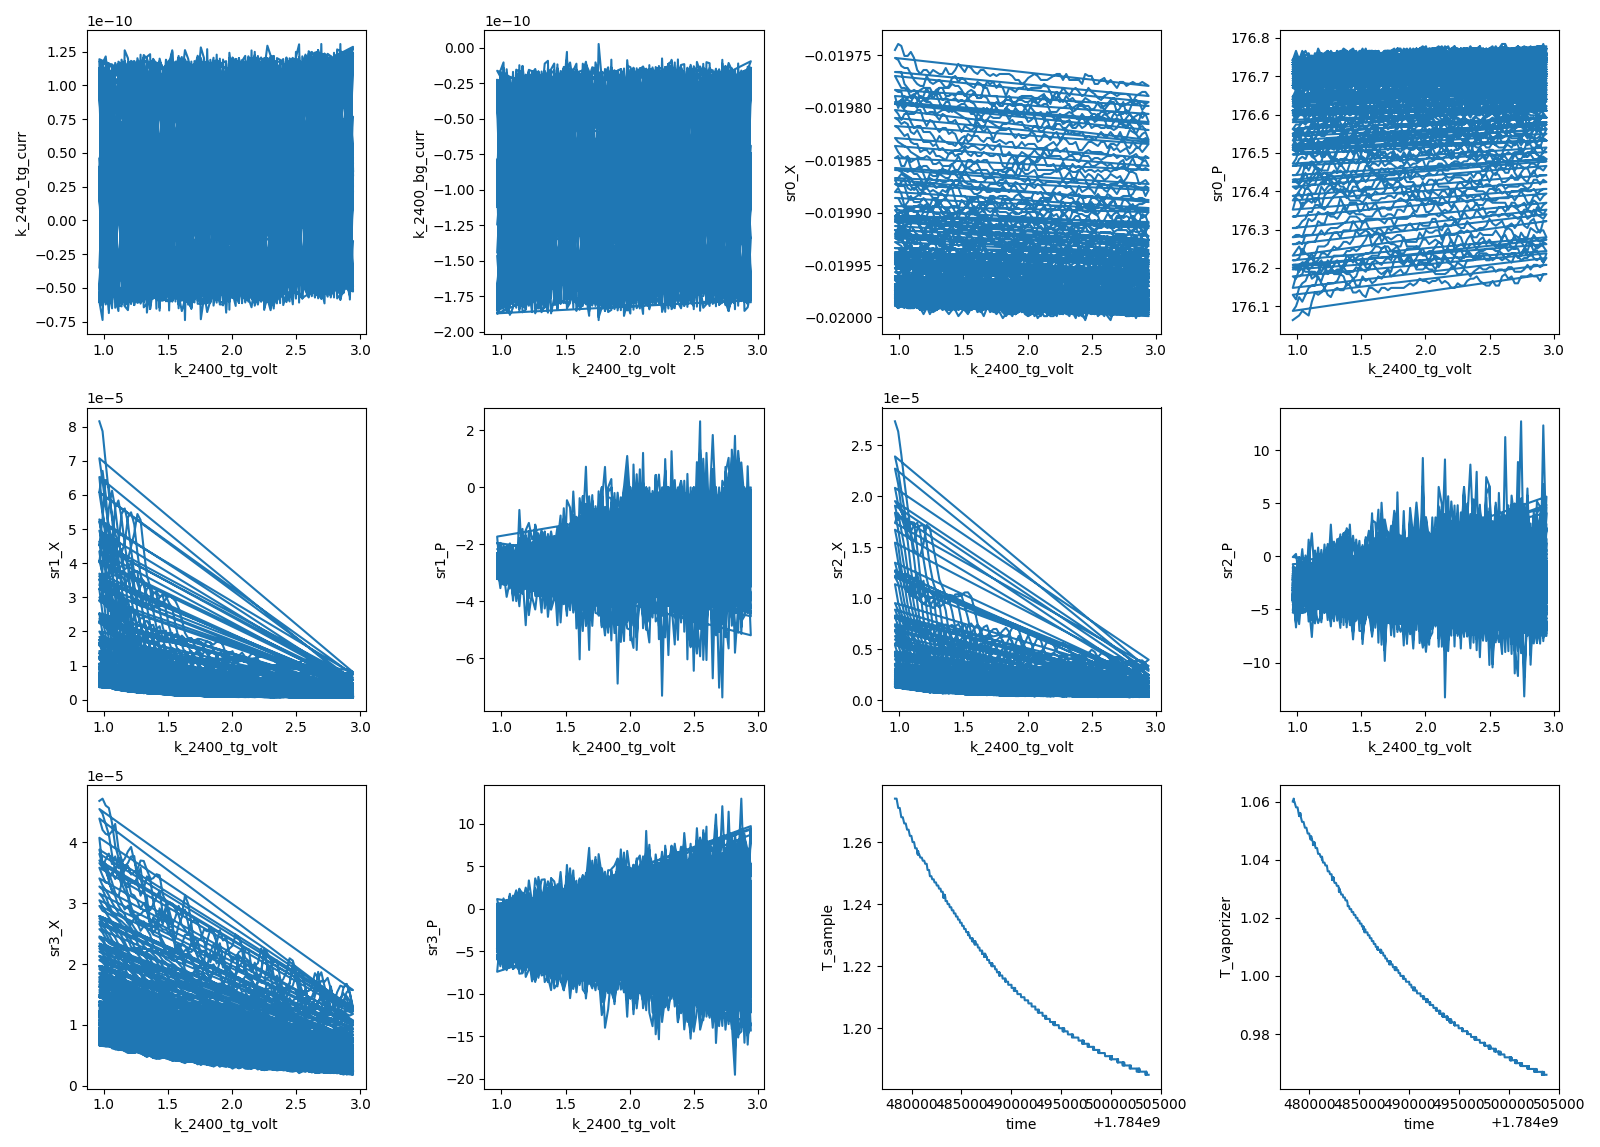

2026-07-19 16:29:28,300 [INFO] Completed in 7h 3m 56s


2026-07-19 16:29:28,301 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260718-QC0426\data\9\data.tsv.gz


fan complete; field at 1.2 T, gates at the n=6.2e12 D=0 point


In [26]:
# === Step 4 — D=0 Landau fan, electron side: B 8 -> 1.2 T (131 rows, 1/B-uniform) x n 2.0 -> 6.2e12 (81 pts) ===
# recipes: landau-fan + landau-fan-vti; per-column SdH-FFT fan; acquisition inherited from spot checks

# --- preconditions ---
_Ts, _B = T_sample(), magnet.field()
print(f"preconditions: T_sample={_Ts:.3f} K (expect 1.0-1.5), B={_B:+.4f} T (expect ~8 after run 8)")
assert 1.0 <= _Ts <= 1.5, f"not at base T: {_Ts:.3f} K"
assert _B > 7.5, f"field not at 8 T: {_B:+.4f} T (fan descends from 8)"

# --- sensitivities: fixed whole-fan, worst-corner (n=2e12 x 8 T) sized ---
sr1.sensitivity(1e-4)
sr2.sensitivity(5e-5)
sr3.sensitivity(1e-4)
sr0.sensitivity(5e-2)
# drive stays 2 V / 20 nA

# --- axes ---
ns_fan = np.linspace(2.0, 6.2, 81)          # 1e12 cm^-2 labels (calibrated scale 1.106x geometry)
Vtgs, Vbgs = d0_point(ns_fan)                # calibrated D=0 line
assert Vtgs.max() < 3.0 and abs(Vbgs).max() < 4.5, "fan line exits validators"
B_vec = field_invB(8.0, 1.2, 131)            # descending, uniform 1/B, d(1/B)=5.4e-3
print(f"fast axis: n {ns_fan[0]}-{ns_fan[-1]}e12, Vtg [{Vtgs.min():+.3f},{Vtgs.max():+.3f}], "
      f"Vbg [{Vbgs.min():+.3f},{Vbgs.max():+.3f}]; slow: B {B_vec[0]:.2f}->{B_vec[-1]:.2f} T x{len(B_vec)}")

meas_config["comments"] = ("landau-fan-vti: D=0, n=2.0->6.2e12 (labels, cal 1.106x) x 81, "
                           "B 8->1.2 T x 131 uniform-1/B (d(1/B)=5.4e-3, spot-check-inherited), "
                           "fast_delay=1.8 (6tau), I_bias=20 nA, sens sr1=1e-4 sr2=5e-5 sr3=1e-4")
s = sweep.AsyncStation(meas_config)
s.add_comment('landau-fan-vti')
s.add_comment('D = 0, n = 2.0 to 6.2e12 cm^-2 (81 pts), B = 8 to 1.2 T (131 rows, 1/B-uniform), electron side; '
              'per-column SdH-FFT fan; onset 1.2 T from run 5; worst corner sized from run-4 R(n) x 16 MR')

# position fast axis at its start (gates are at the hole point after run 8)
s.ramp(k_tg.volt, Vtgs[0])
s.ramp(k_bg.volt, Vbgs[0])
interruptible_sleep(10)

s.fp(T_sample).fp(T_vaporizer)
s.fp(magnet.field)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
for _l in (sr0, sr1, sr2, sr3):
    s.fp(_l.X).fp(_l.P)
s.plot(k_tg.volt, k_tg.curr)
s.plot(k_tg.volt, k_bg.curr)
for _l in (sr0, sr1, sr2, sr3):
    s.plot(k_tg.volt, _l.X)
    s.plot(k_tg.volt, _l.P)
s.plot('time', T_sample)
s.plot('time', T_vaporizer)

s.multimegasweep([magnet.field], [B_vec], [k_tg.volt, k_bg.volt], [Vtgs, Vbgs],
                 slow_delay=1, fast_delay=1.8)
print("fan complete; field at 1.2 T, gates at the n=6.2e12 D=0 point")


## HERA — Step 5 Verify: LK mass ladder (temperature-dependence-vti, Flavor B)

Recipes: `temperature-dependence.md` Flavor B + the **mandatory VTI guard set** (`temperature-dependence-vti`): hover acceptance (stable-not-proximate: spread < 0.1 K over 90 s within [T−0.5, T+3]), logfile-freshness guard on every settle poll (fault at age > 15 s ≈ 3 write periods), direction-aware runaway guard (fault only if T_vap rises > 2 K above both rung-start and target), alternating B-sweep direction derived from the live field. `ratio = 0.95` per the card (deviation consent-gated); all targets ≪ the 100 K cap.

**What it decides (the investigation's decisive cross-check):** per-tone LK masses at the characterized point. Model: ML ≈ 0.02–0.05, BL ≈ 0.065–0.07, ABC ≈ 0.043–0.05; a **breakdown/mixing tone damps with the parents' summed mass ≈ 0.09** — so the F_L tone's fitted mass separates ABC-pocket from breakdown outright (beat exclusion: a coexisting tone *lighter* than the main branch cannot be a beat). Two distinct masses on {ML, BL} confirm two genuine bands (ABA); the F_L tone's mass makes the sr1-region call.

**Design:** fixed point n_label = 6.0×10¹², D = 0, electron side (Vtg +2.848, Vbg +2.216). B window 2.8→6.0 T, ΔB 36 mT uniform-B (1.5× Nyquist at 2.8 T for F_max 72), 90 pts/leg — δF ≈ 5.3 T, all pairwise tone separations ≥ 13 T ≈ 2.5·δF ✓. Ladder **ascending** {base, 10, 13, 16, 20, 25 K} — deviation from base-recipe warm-first, stated: VTI up-legs catch in 2.5–4 min (rig card) while any descent is passive-cooling-limited; T is fp'd per point and rungs are accepted on stability, so labels are nominal. Sweep direction alternates from live field (leg 1: 2.8→6.0; leg 2: 6.0→2.8; …) — never re-traverses. e-temp floor ≈ 8 K makes lattice rungs below ~9 K redundant — the ladder concentrates its lever above the floor with the base rung as anchor.

**Price:** per rung ≈ hover (3–10 min) + sweep (23 min traverse floor + 6 min reads ≈ 29 min) → 6 rungs ≈ **3.7 h nominal, 4–4.5 h realistic**. Ends: heaters off, passive return to base. Sens unchanged from run 6 (R(T) drift at 25 K is modest; first-rows check per rung watches fs).

**Checkpoints:** per-rung first rows (fs, T stability on the fp'd trace) via the armed watches; rung-completion digest reads. Runs land as one file per rung (expected ids 10–15).


preconditions: T_sample=1.185 K (expect base), B=+1.2034 T (expect ~1.2 after fan), heater ranges=0/0 (expect 0/0)


gates at (+2.849, +2.216) (n=6.0e12, D=0)
rung base: T=1.185 K, no heating


2026-07-19 16:48:55,556 [INFO] Starting sweep with ID 10


2026-07-19 16:48:55,556 [INFO] Minimum duration 0h 0m 0s


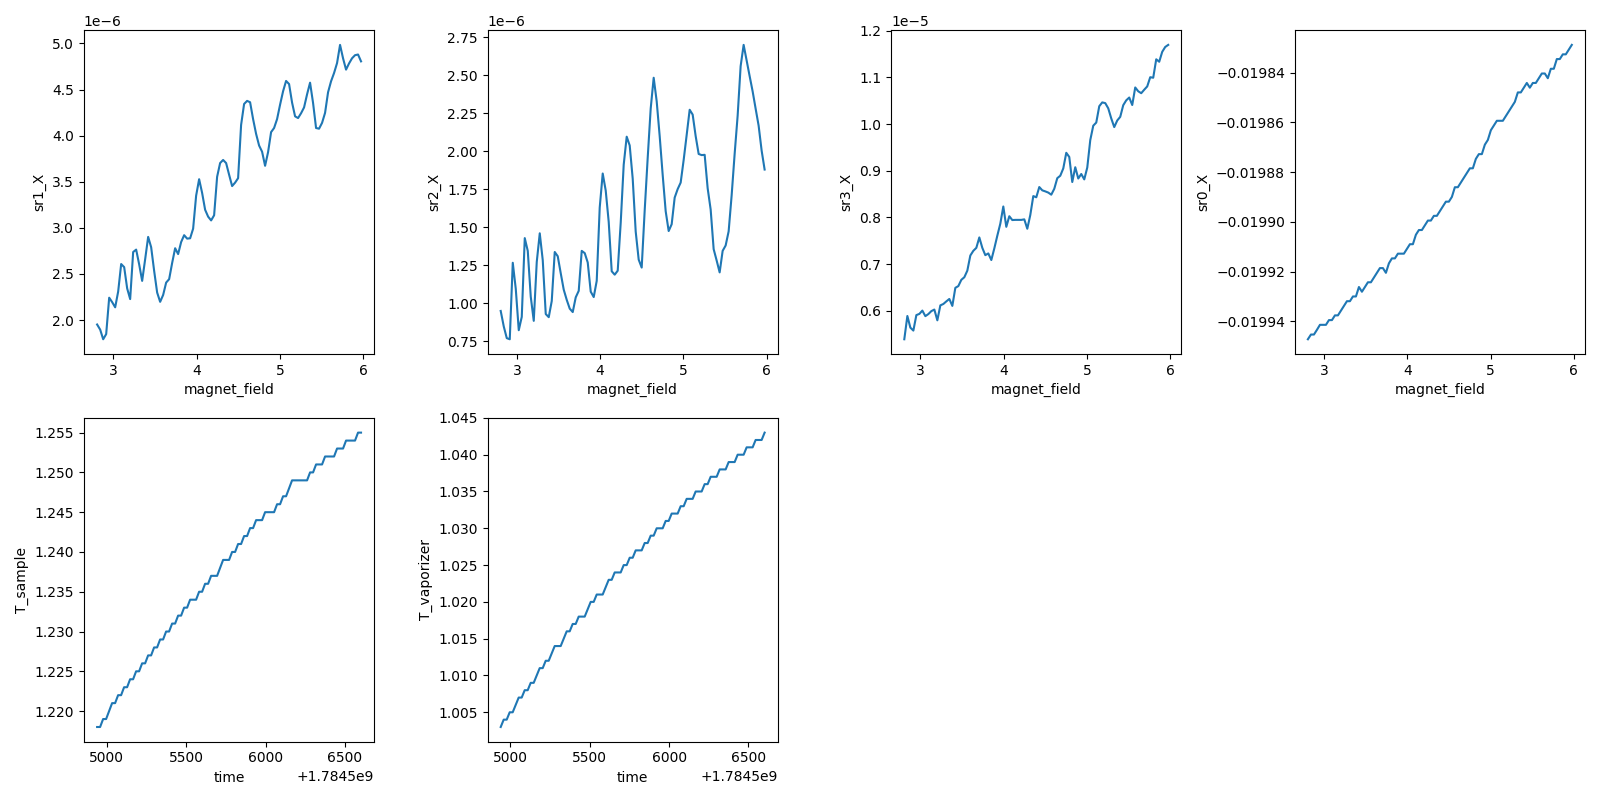

2026-07-19 17:16:42,862 [INFO] Completed in 0h 27m 46s


2026-07-19 17:16:42,863 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260718-QC0426\data\10\data.tsv.gz


rung base sweep done (run dir written); B at +5.98 T


rung 10.0 K: ranges 1/1 (expect nonzero)


rung 10.0 K accepted at T=10.008 K (hover)
2026-07-19 17:27:17,914 [INFO] Starting sweep with ID 11


2026-07-19 17:27:17,915 [INFO] Minimum duration 0h 0m 0s


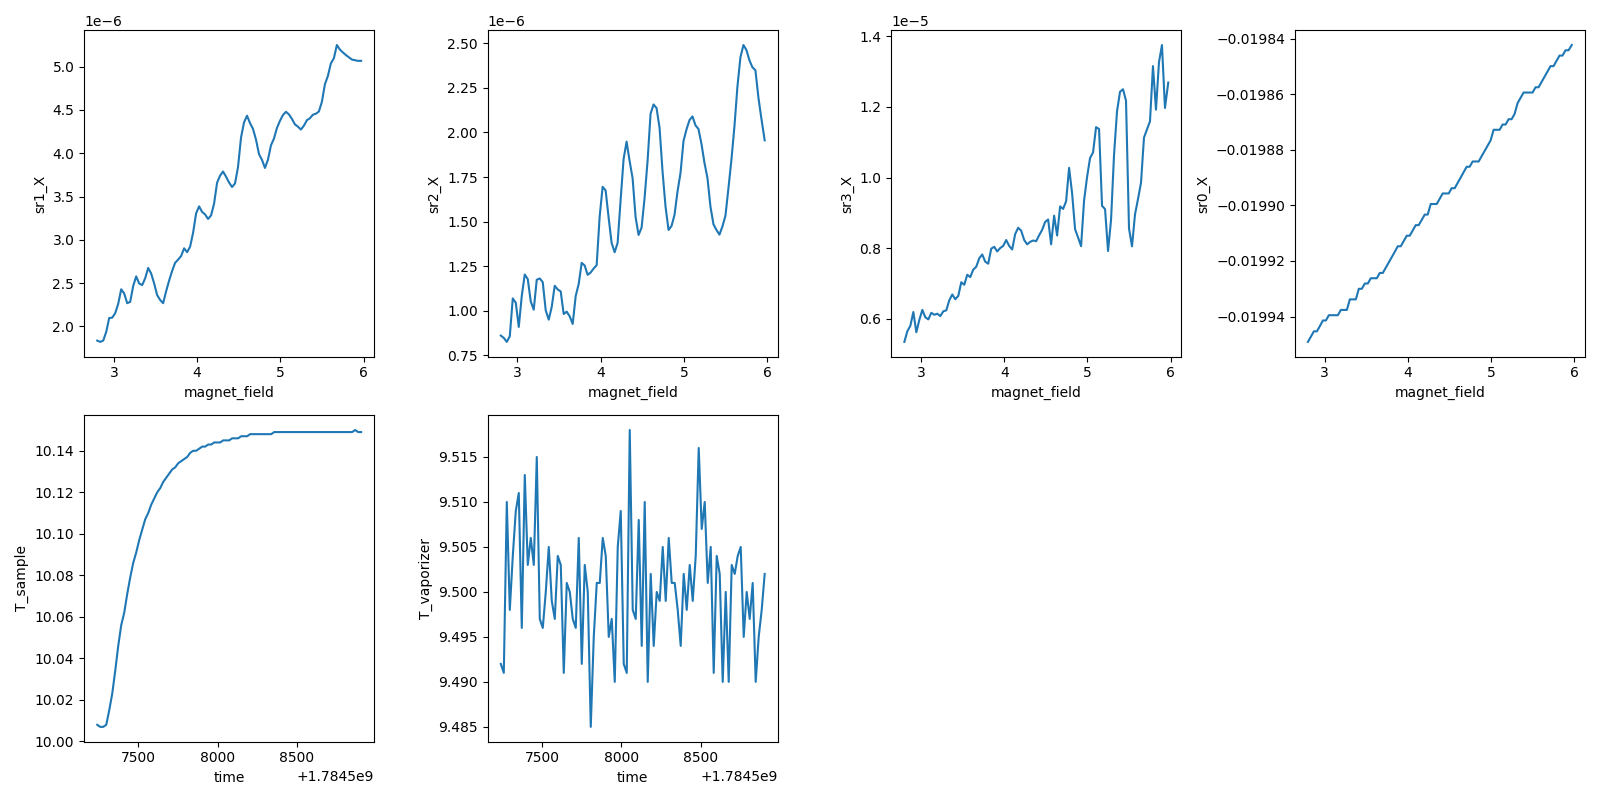

2026-07-19 17:55:05,159 [INFO] Completed in 0h 27m 46s


2026-07-19 17:55:05,160 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260718-QC0426\data\11\data.tsv.gz


rung 10K sweep done (run dir written); B at +2.80 T


rung 13.0 K: ranges 1/1 (expect nonzero)


rung 13.0 K accepted at T=13.012 K (hover)
2026-07-19 17:56:40,206 [INFO] Starting sweep with ID 12


2026-07-19 17:56:40,207 [INFO] Minimum duration 0h 0m 0s


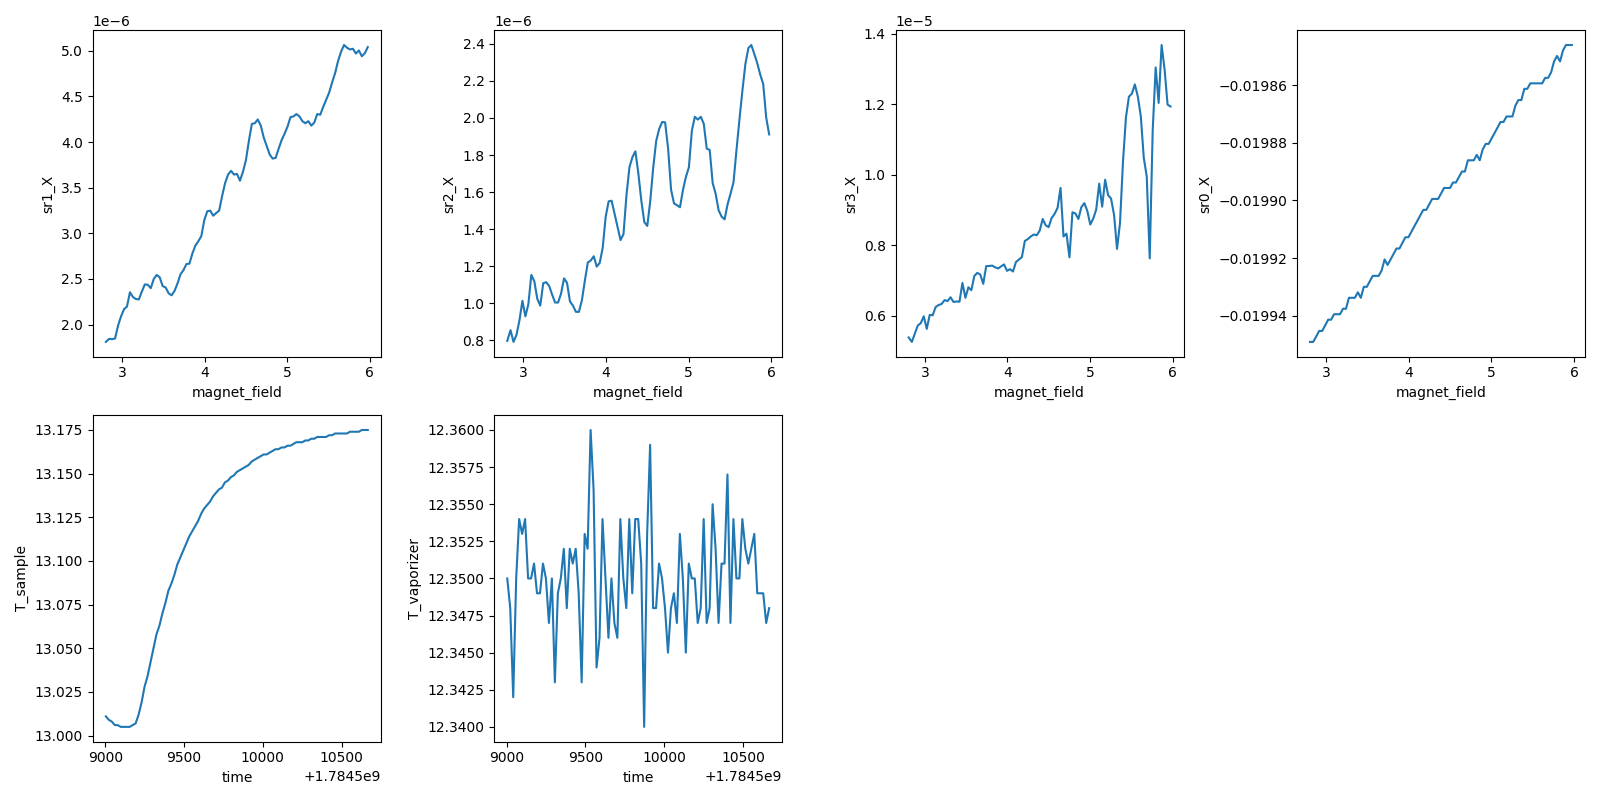

2026-07-19 18:24:27,401 [INFO] Completed in 0h 27m 46s


2026-07-19 18:24:27,402 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260718-QC0426\data\12\data.tsv.gz


rung 13K sweep done (run dir written); B at +5.98 T


rung 16.0 K: ranges 1/1 (expect nonzero)


rung 16.0 K accepted at T=16.011 K (hover)
2026-07-19 18:26:12,426 [INFO] Starting sweep with ID 13


2026-07-19 18:26:12,427 [INFO] Minimum duration 0h 0m 0s


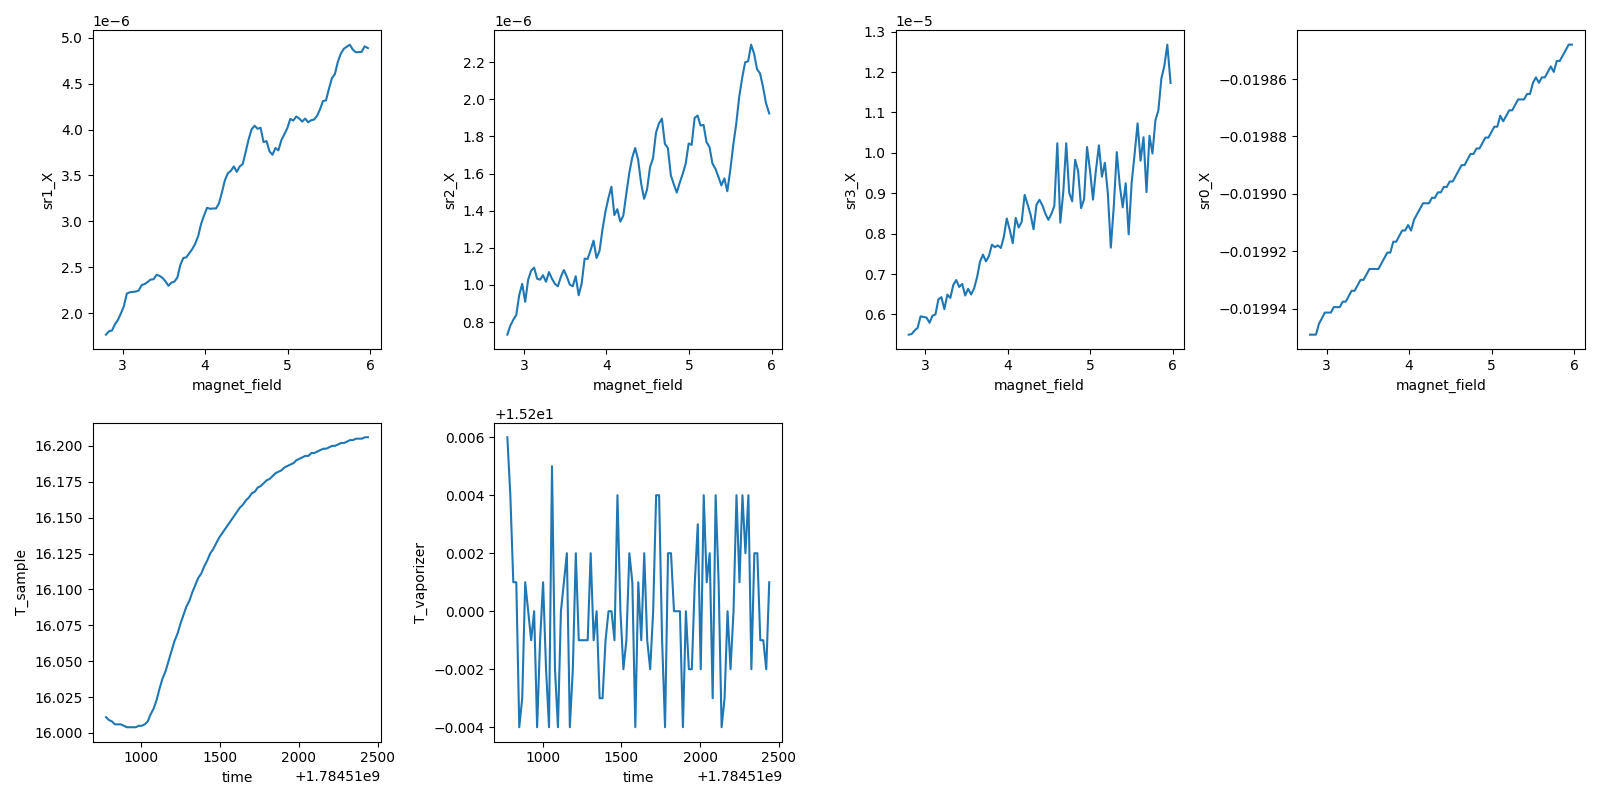

2026-07-19 18:53:59,530 [INFO] Completed in 0h 27m 46s


2026-07-19 18:53:59,531 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260718-QC0426\data\13\data.tsv.gz


rung 16K sweep done (run dir written); B at +2.80 T


rung 20.0 K: ranges 2/2 (expect nonzero)


rung 20.0 K accepted at T=20.004 K (hover)
2026-07-19 18:55:44,545 [INFO] Starting sweep with ID 14


2026-07-19 18:55:44,546 [INFO] Minimum duration 0h 0m 0s


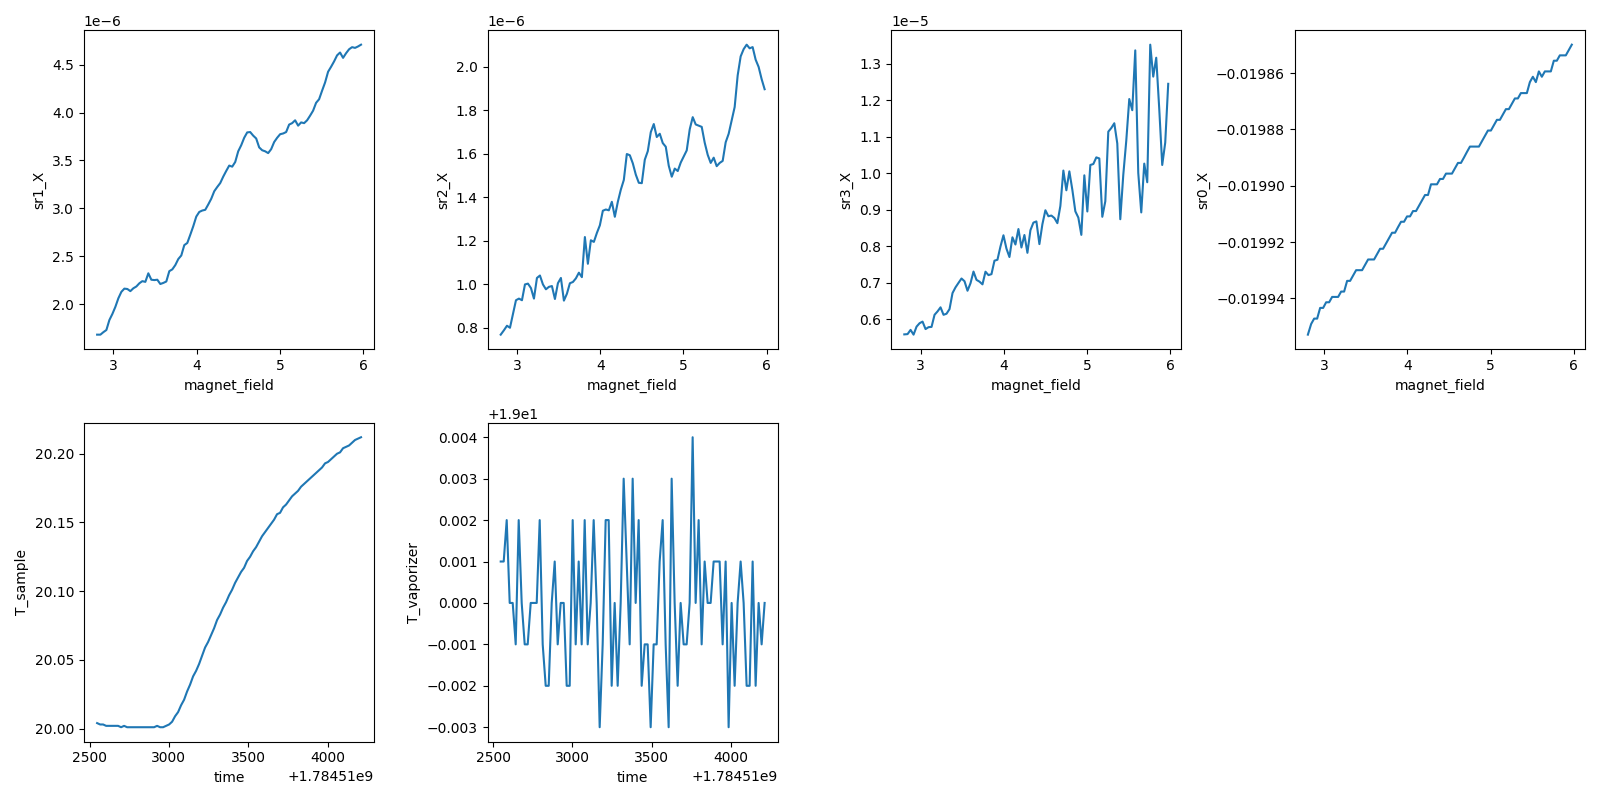

2026-07-19 19:23:31,529 [INFO] Completed in 0h 27m 46s


2026-07-19 19:23:31,530 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260718-QC0426\data\14\data.tsv.gz


rung 20K sweep done (run dir written); B at +5.98 T


rung 25.0 K: ranges 2/2 (expect nonzero)


rung 25.0 K accepted at T=25.005 K (hover)
2026-07-19 19:25:16,566 [INFO] Starting sweep with ID 15


2026-07-19 19:25:16,567 [INFO] Minimum duration 0h 0m 0s


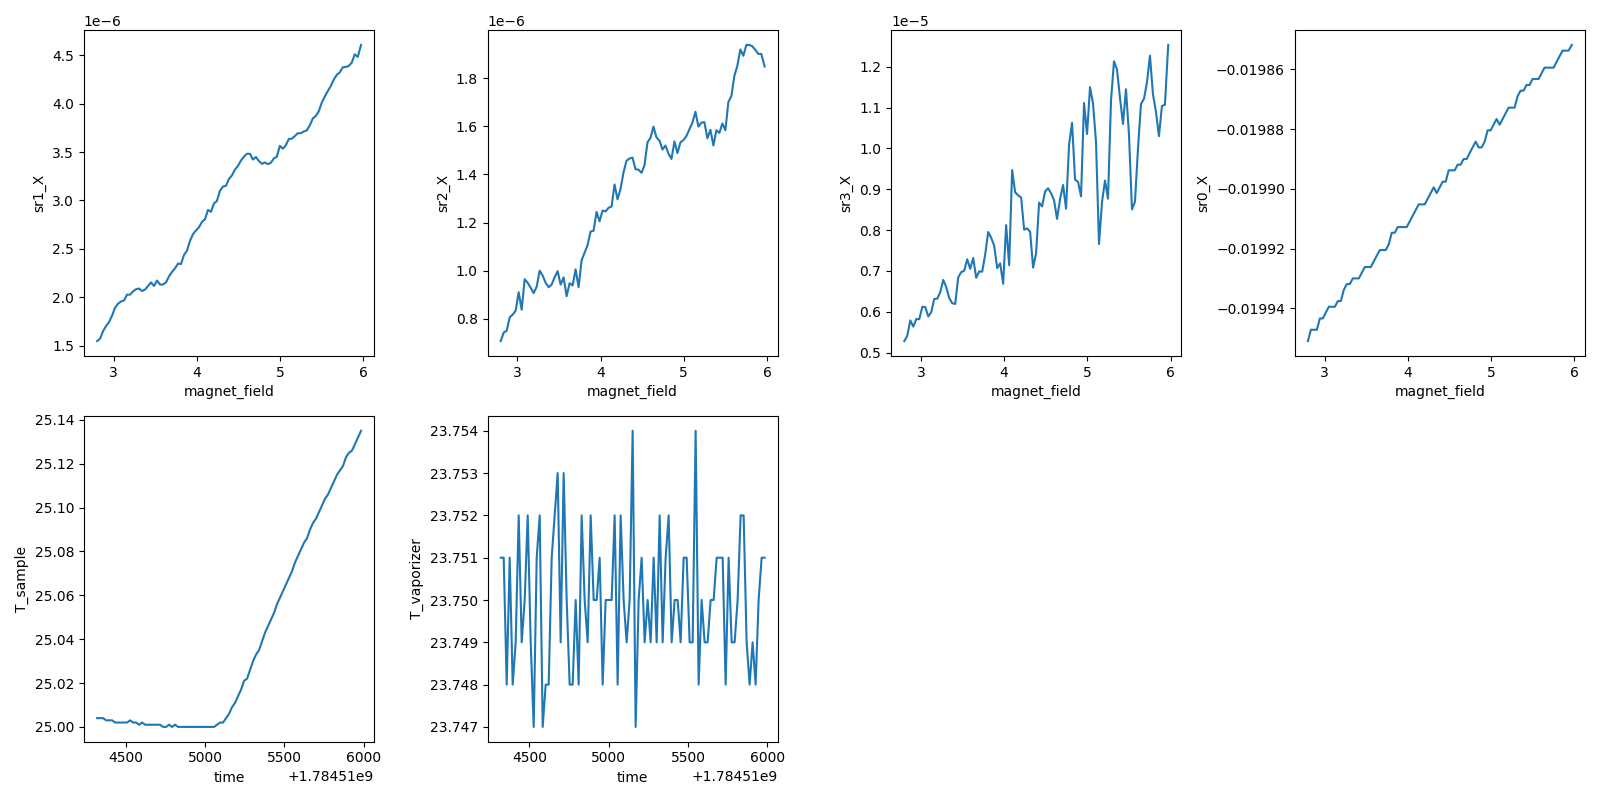

2026-07-19 19:53:03,562 [INFO] Completed in 0h 27m 46s


2026-07-19 19:53:03,563 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260718-QC0426\data\15\data.tsv.gz


rung 25K sweep done (run dir written); B at +2.80 T
ladder complete; heaters off, passive return to base; field holds at last sweep end


In [27]:
# === Step 5 Verify — LK mass ladder: n=6.0e12 D=0 electron point, B 2.8-6.0 T, T {base,10,13,16,20,25} K ===
# recipes: temperature-dependence (Flavor B) + temperature-dependence-vti guard set (mandatory)
import os

# --- preconditions ---
_Ts, _B = T_sample(), magnet.field()
print(f"preconditions: T_sample={_Ts:.3f} K (expect base), B={_B:+.4f} T (expect ~1.2 after fan), "
      f"heater ranges={heater.sample_range()}/{heater.vaporizer_range()} (expect 0/0)")
assert 1.0 <= _Ts <= 1.5, f"not at base T: {_Ts:.3f} K"
assert 1.0 < _B < 3.0, f"unexpected field: {_B:+.4f} T"
assert heater.sample_range() == 0 and heater.vaporizer_range() == 0, "heaters not off at ladder start"

vtg_pt, vbg_pt = d0_point(6.0)
k_tg.volt(vtg_pt); k_bg.volt(vbg_pt)
interruptible_sleep(10)
print(f"gates at ({k_tg.volt():+.3f}, {k_bg.volt():+.3f}) (n=6.0e12, D=0)")

B_LO, B_HI, DB = 2.8, 6.0, 0.036
B_up = np.arange(B_LO, B_HI + 1e-9, DB)
RUNGS = [None, 10.0, 13.0, 16.0, 20.0, 25.0]   # None = base rung, no heating

_lf = [p for p in VTI.temp_logfile_candidates["T_sample"] if os.path.exists(p)][0]

def _fresh():
    age = time.time() - os.path.getmtime(_lf)
    assert age < 15, f"T logfile stale ({age:.0f} s) — worker dead? aborting ladder"

def wait_hover(target, tv_start, timeout_s=2400):
    """VTI hover acceptance: stable (spread<0.1 K over 90 s) within [target-0.5, target+3]."""
    t0 = time.time()
    hist = []
    while time.time() - t0 < timeout_s:
        _fresh()
        T_now, Tv_now = T_sample(), T_vaporizer()
        hist.append((time.time(), T_now))
        # direction-aware runaway guard: fault only on true runaway heating
        if Tv_now > max(tv_start, target) + 2.0:
            heater.off('both')
            raise RuntimeError(f"runaway: T_vap={Tv_now:.2f} K > start/target + 2; heaters off")
        recent = [h for h in hist if h[0] > time.time() - 90]
        if len(recent) >= 7:
            Ts = [h[1] for h in recent]
            if (max(Ts) - min(Ts) < 0.1) and (target - 0.5 <= T_now <= target + 3.0):
                return T_now
        interruptible_sleep(10)
    heater.off('both')
    raise RuntimeError(f"hover timeout at target {target} K; heaters off")

for i, rung in enumerate(RUNGS):
    tv_start = T_vaporizer()
    if rung is not None:
        heater.set_both(rung, ratio=0.95)          # sanctioned method; ratio fixed per card
        interruptible_sleep(5)
        r_s, r_v = heater.sample_range(), heater.vaporizer_range()
        print(f"rung {rung} K: ranges {r_s}/{r_v} (expect nonzero)")
        assert r_s > 0 and r_v > 0, "set_both did not enable heater ranges"
        T_acc = wait_hover(rung, tv_start)
        print(f"rung {rung} K accepted at T={T_acc:.3f} K (hover)")
    else:
        print(f"rung base: T={T_sample():.3f} K, no heating")

    # alternate sweep direction from the live field (never re-traverse)
    _Bnow = magnet.field()
    vec = B_up if abs(_Bnow - B_LO) < abs(_Bnow - B_HI) else B_up[::-1]
    if abs(magnet.field() - vec[0]) > 0.05:
        magnet.field(vec[0])                       # blocking pre-position

    lab = f"{rung:.0f}K" if rung is not None else "base"
    meas_config["comments"] = (f"temperature-dependence-vti Flavor B (LK): rung {lab}, n=6.0e12 D=0 electron, "
                               f"B {vec[0]:.1f}->{vec[-1]:.1f} T x{len(vec)} (dB=36 mT), I_bias=20 nA")
    s = sweep.AsyncStation(meas_config)
    s.add_comment('temperature-dependence-vti')
    s.add_comment(f'LK mass ladder rung {lab} (nominal; per-point T is the fit axis), '
                  f'fixed point Vtg={vtg_pt:+.3f} Vbg={vbg_pt:+.3f}, alternating sweep dir')
    s.fp(T_sample).fp(T_vaporizer)
    s.fp(magnet.field)
    s.fp(k_tg.volt).fp(k_tg.curr)
    s.fp(k_bg.volt).fp(k_bg.curr)
    for _l in (sr0, sr1, sr2, sr3):
        s.fp(_l.X).fp(_l.P)
    s.plot(magnet.field, sr1.X)
    s.plot(magnet.field, sr2.X)
    s.plot(magnet.field, sr3.X)
    s.plot(magnet.field, sr0.X)
    s.plot('time', T_sample)
    s.plot('time', T_vaporizer)
    s.sweep(magnet.field, vec, delay=0)
    print(f"rung {lab} sweep done (run dir written); B at {magnet.field():+.2f} T")

heater.off('both')
print("ladder complete; heaters off, passive return to base; field holds at last sweep end")


## HERA — session park

Campaign call delivered (ana cell 29). Parking: gates to 0, field 2.8 → 0 T (blocking, ~20 min), heaters already off (passive return to base in progress). Leaves the rig in the handover state: B = 0, gates 0, Si 0, base T.

In [28]:
# === Session park: field to zero, gates to zero, heaters confirmed off ===
_Ts = T_sample()
print(f"pre-park: T={_Ts:.2f} K (passive descent from ladder), B={magnet.field():+.3f} T, "
      f"gates ({k_tg.volt():+.3f}, {k_bg.volt():+.3f}), ranges {heater.sample_range()}/{heater.vaporizer_range()}")
k_tg.volt(0)
k_bg.volt(0)
magnet.field(0.0)   # blocking ramp ~20 min from 2.8 T
print(f"parked: B={magnet.field():+.4f} T, gates ({k_tg.volt():+.3f}, {k_bg.volt():+.3f}), "
      f"T={T_sample():.2f} K, DC205 {dc205.voltage():+.3f} V")


pre-park: T=24.26 K (passive descent from ladder), B=+2.803 T, gates (+2.849, +2.216), ranges 0/0


parked: B=-0.0001 T, gates (+0.000, +0.000), T=1.19 K, DC205 +0.000 V


## HERA — LK mass ladder v2 (X-designed top; supersedes runs 10–15's ML fit)

Operator-directed re-run under the new ladder-top guidance: size the top from the **lightest** expected mass — X = 14.69·(m*/mₑ)·T/B_eff ≳ 3 at the top, 5+ rungs spanning X ≈ 0.5–3. With m_ML = 0.019 (measured, runs 10–15) and B_eff = 3.82 T: rungs **{base, 10, 15, 21, 29, 41} K** → X_ML ≈ {floor, 0.73, 1.10, 1.54, 2.12, 3.00} (41 K leaves ML at ~0.15 amplitude). Heavy tones (0.052–0.057) reach X ≈ 2.2–4.6 by 21 K — their fits keep full coverage on the low rungs. Ladder v1's deficiency: ML topped at X = 1.8 / amplitude 0.55 — ill-conditioned per the rule; its ±0.0008 formal error was optimistic.

**Protocol additions vs v1:** (1) base rung re-measured fresh — normalization anchor plus a reproduction check against run 10 across the 25 K thermal cycle; (2) **extend-while-hot**: the ladder cell ends at the 41 K rung with **heaters still ON and holding** — HERA re-fits the ML amplitude curve as that run lands and executes exactly one of the two cells that follow: the 50 K extension rung (X ≈ 3.7; if A_ML(41)/A_ML(base) > ~0.2 or the fit is still loose) or the shutdown cell (heaters off, passive to base). Lifting further while hot is cheap; re-heating later is not.

Acquisition identical to v1 (comparability): same point (n_label 6.0, D = 0 electron), B 2.8→6.0 T × 89 at 36 mT, alternating direction from live field, same sensitivities and 20 nA drive, full VTI guard set, ratio 0.95. All targets ≪ the 100 K cap; B ≤ 6 T keeps every rung outside the T/B consideration zone.

**Price:** field ramp 0→2.8 T (~20 min) + 6 rungs × (hover 3–8 min + 28 min sweep) ≈ **4–4.5 h**, plus the extension decision (+~40 min if taken). Runs expected: 16 (base′), 17–21 (heated rungs), 22 (extension, conditional). Checkpoints: per-rung digests via watches; fp'd T verified per rung; sensitivities watched at the hot rungs (phonon R growth).


preconditions: T_sample=1.181 K (expect base after park), B=+0.0034 T (expect ~0), heater ranges=0/0 (expect 0/0)


gates at (+2.849, +2.216) (n=6.0e12, D=0 electron point)


rung base: T=1.233 K
2026-07-19 20:55:12,856 [INFO] Starting sweep with ID 16


2026-07-19 20:55:12,857 [INFO] Minimum duration 0h 0m 0s


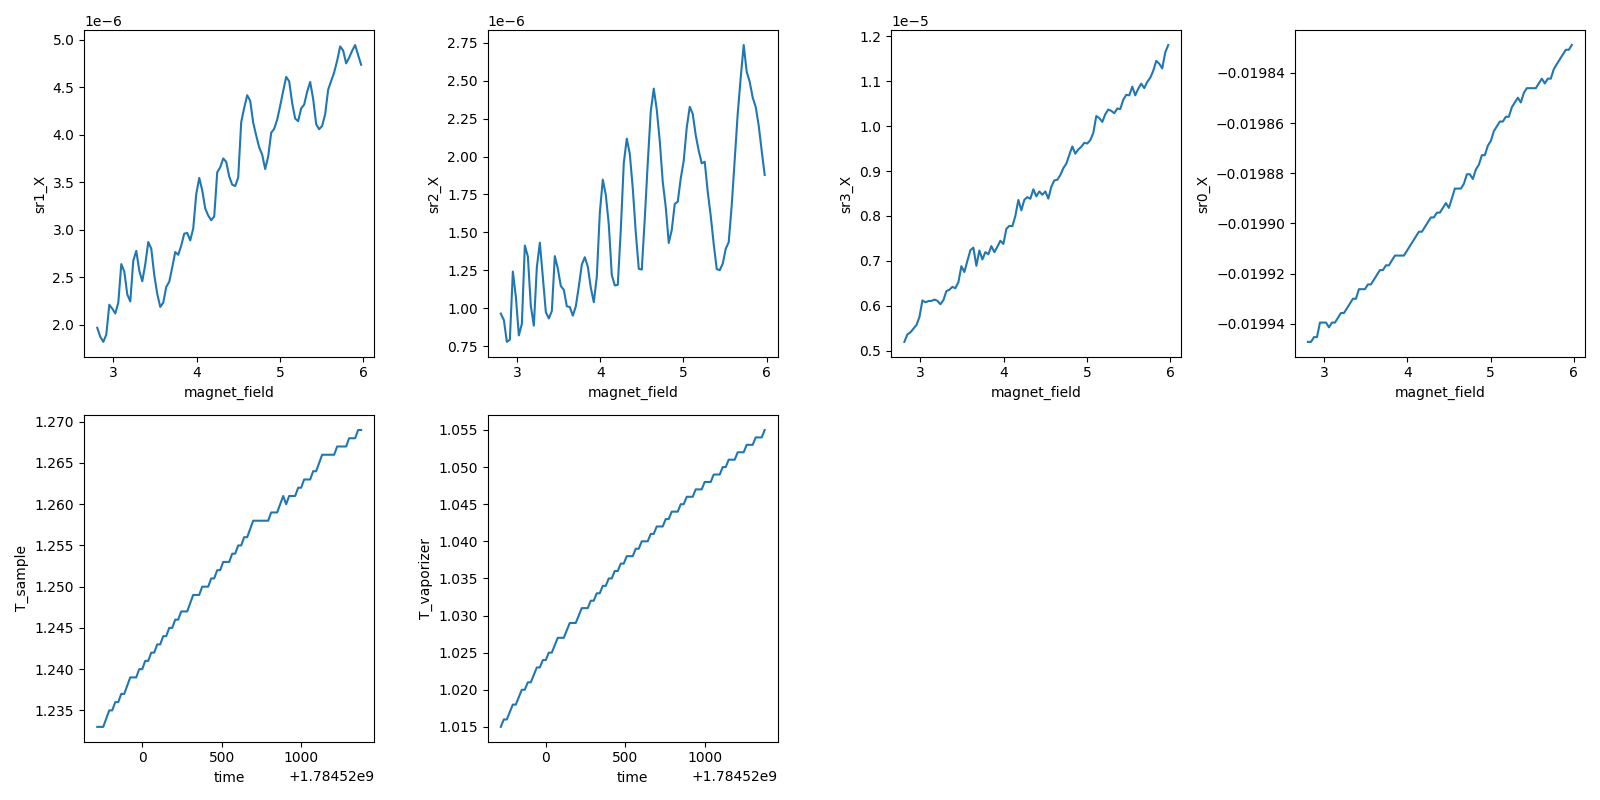

2026-07-19 21:22:59,890 [INFO] Completed in 0h 27m 46s


2026-07-19 21:22:59,892 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260718-QC0426\data\16\data.tsv.gz


rung base2 sweep done; B at +5.98 T


rung 10.0 K accepted at T=10.010 K (hover)
2026-07-19 21:25:24,926 [INFO] Starting sweep with ID 17


2026-07-19 21:25:24,926 [INFO] Minimum duration 0h 0m 0s


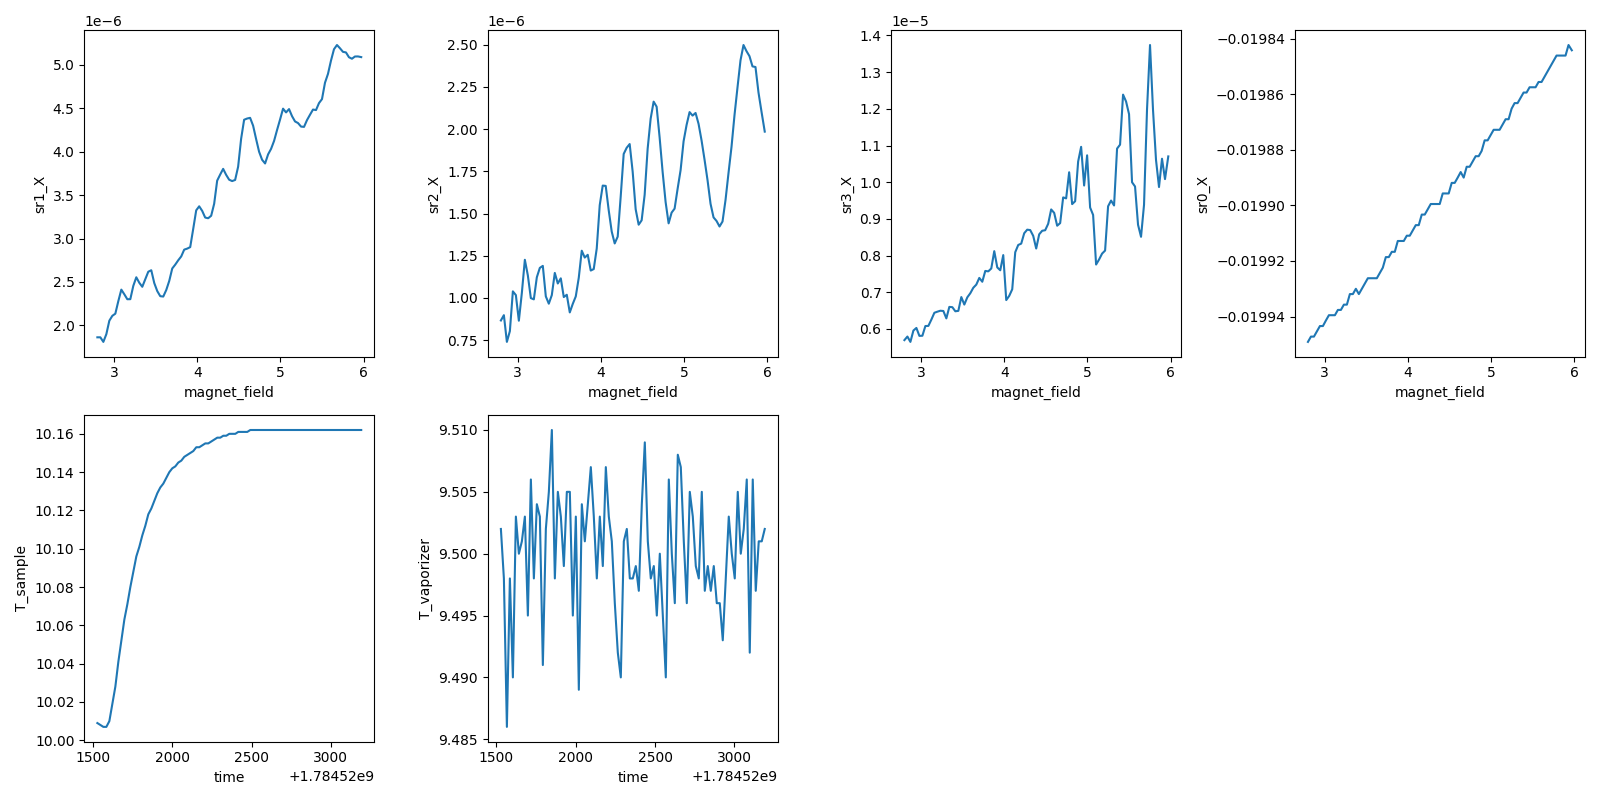

2026-07-19 21:53:11,866 [INFO] Completed in 0h 27m 46s


2026-07-19 21:53:11,867 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260718-QC0426\data\17\data.tsv.gz


rung 10K sweep done; B at +2.80 T


rung 15.0 K accepted at T=15.011 K (hover)
2026-07-19 21:55:06,910 [INFO] Starting sweep with ID 18


2026-07-19 21:55:06,910 [INFO] Minimum duration 0h 0m 0s


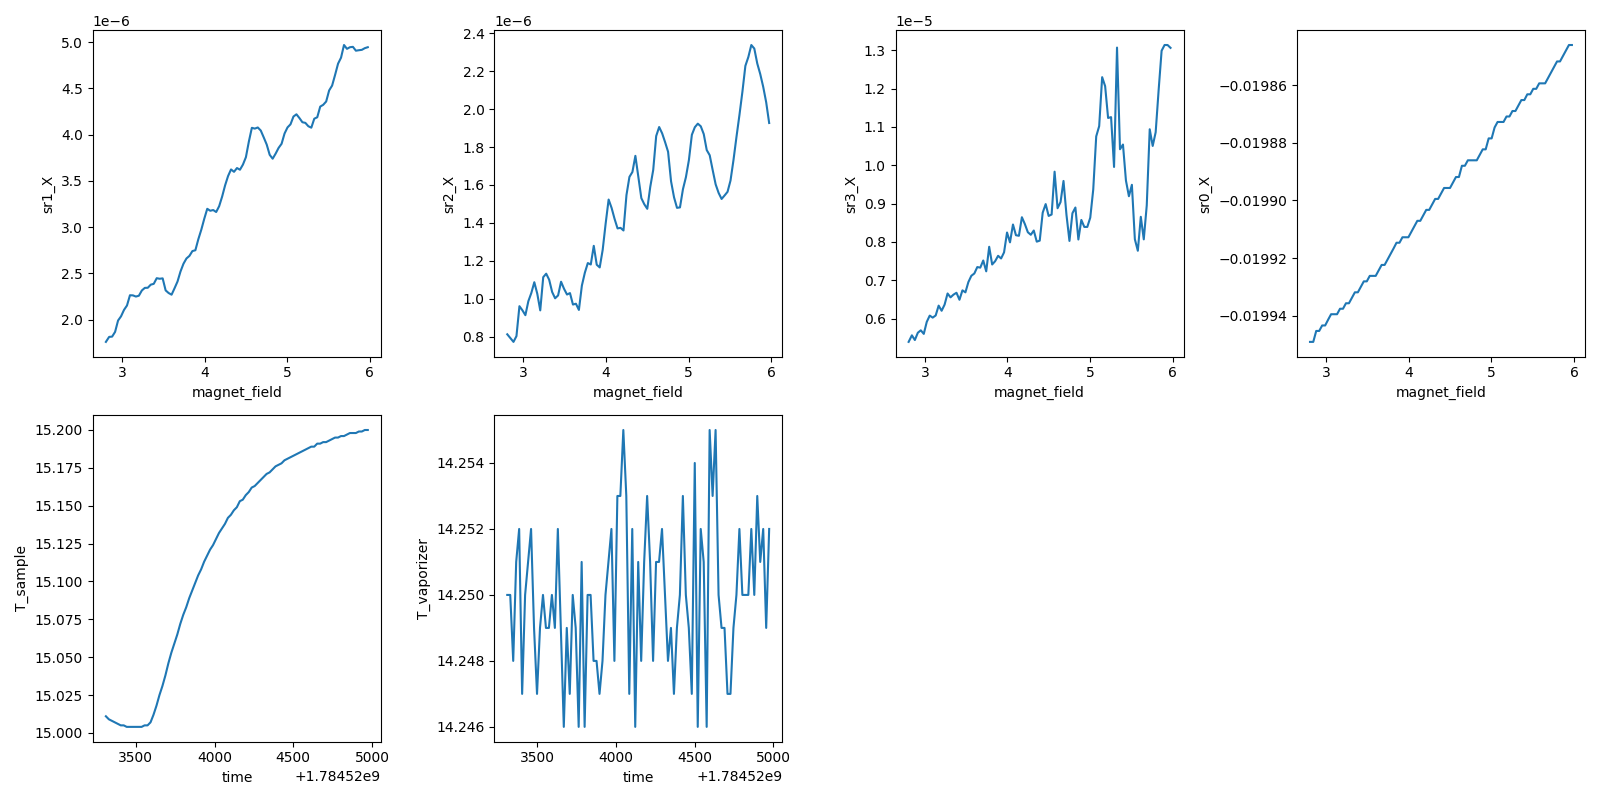

2026-07-19 22:22:53,864 [INFO] Completed in 0h 27m 46s


2026-07-19 22:22:53,865 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260718-QC0426\data\18\data.tsv.gz


rung 15K sweep done; B at +5.98 T


rung 21.0 K accepted at T=21.005 K (hover)
2026-07-19 22:24:48,883 [INFO] Starting sweep with ID 19


2026-07-19 22:24:48,884 [INFO] Minimum duration 0h 0m 0s


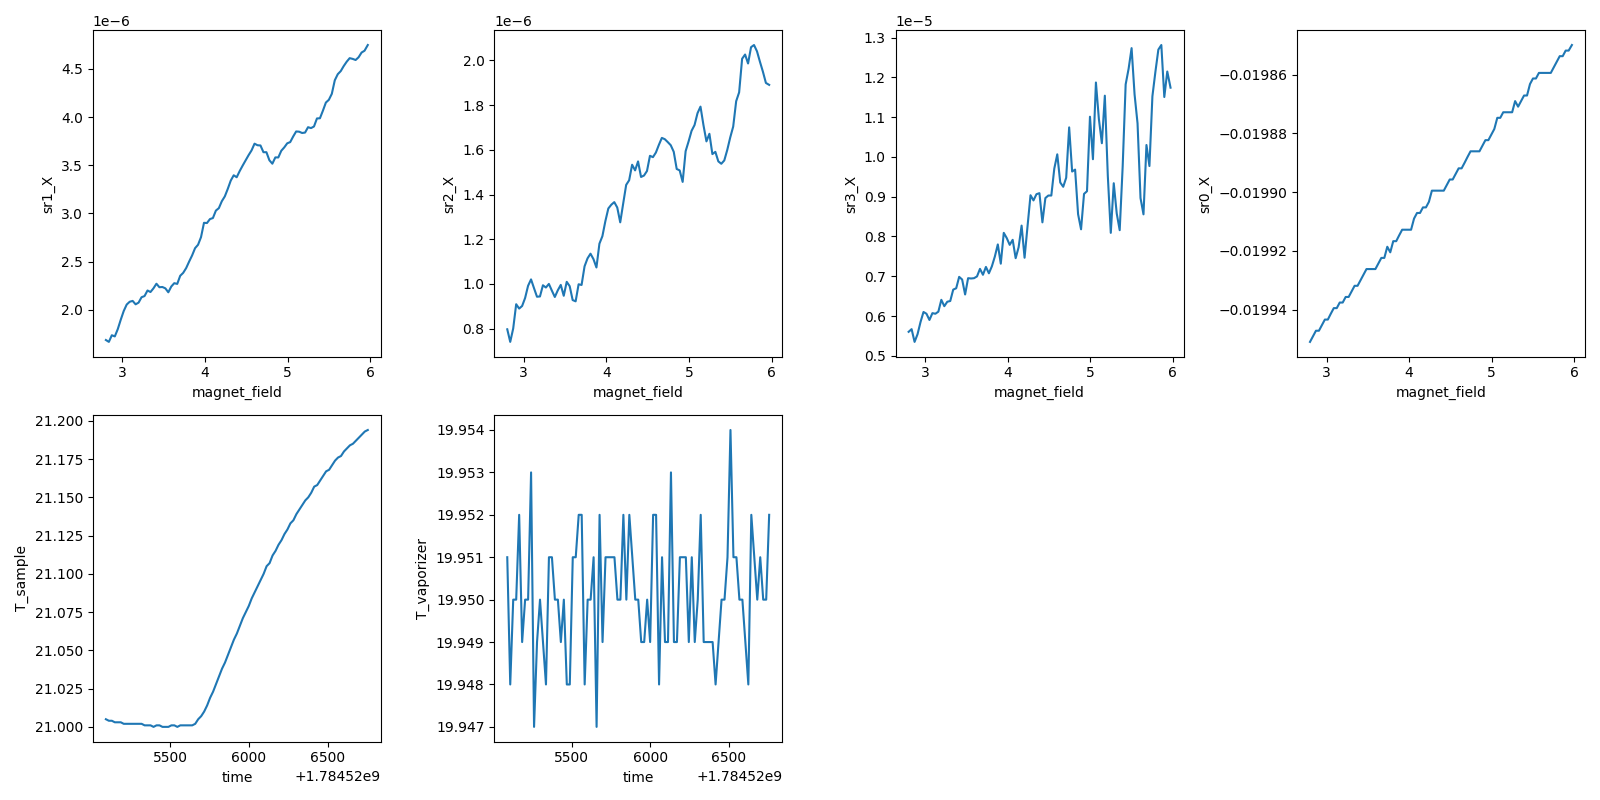

2026-07-19 22:52:35,828 [INFO] Completed in 0h 27m 46s


2026-07-19 22:52:35,829 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260718-QC0426\data\19\data.tsv.gz


rung 21K sweep done; B at +2.80 T


rung 29.0 K accepted at T=29.005 K (hover)
2026-07-19 22:54:30,868 [INFO] Starting sweep with ID 20


2026-07-19 22:54:30,869 [INFO] Minimum duration 0h 0m 0s


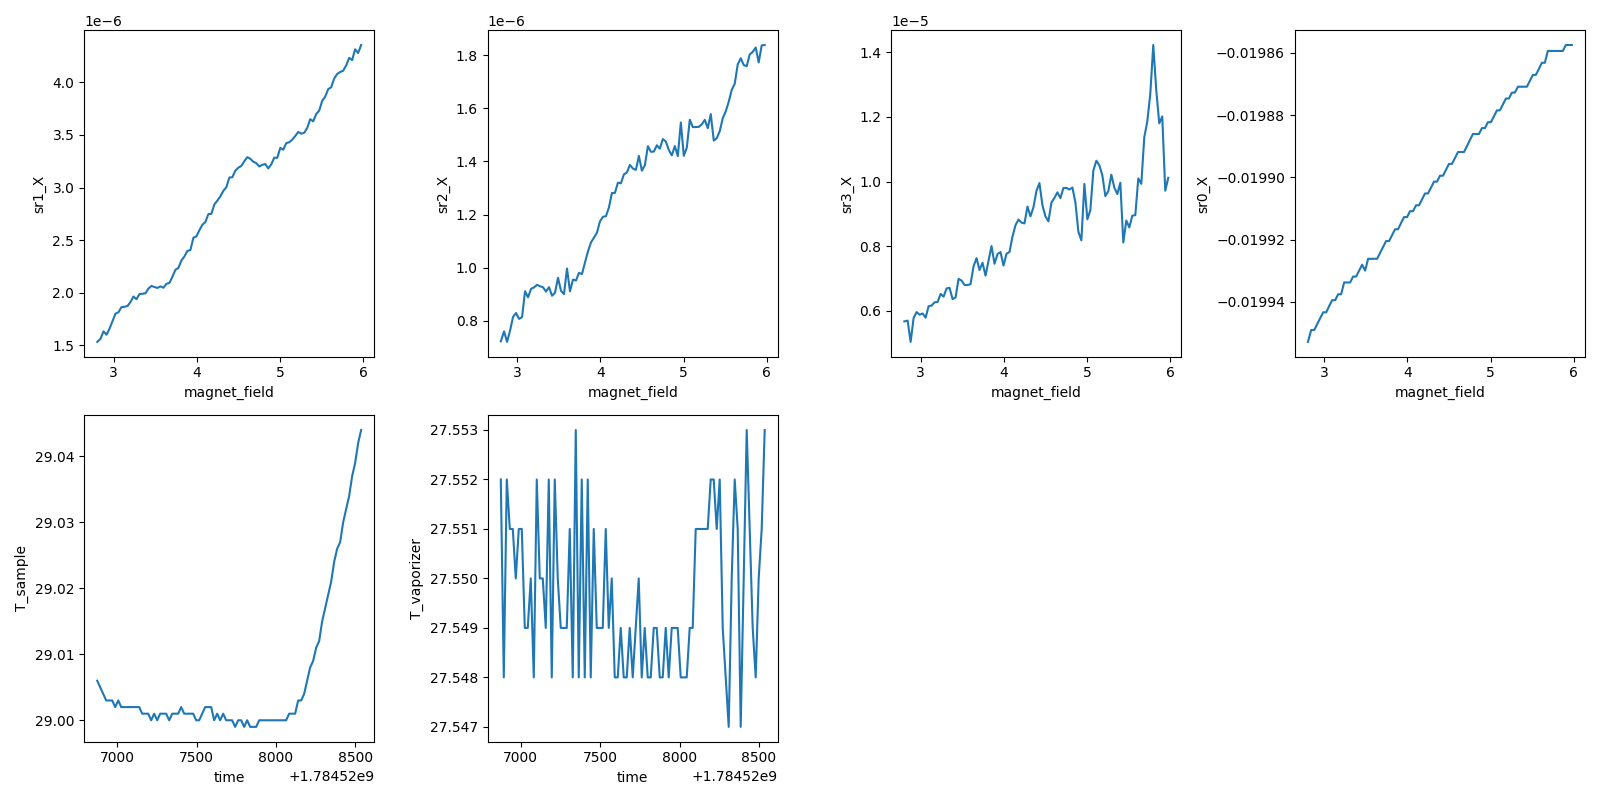

2026-07-19 23:22:17,617 [INFO] Completed in 0h 27m 45s


2026-07-19 23:22:17,617 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260718-QC0426\data\20\data.tsv.gz


rung 29K sweep done; B at +5.98 T


rung 41.0 K accepted at T=41.006 K (hover)
2026-07-19 23:24:42,648 [INFO] Starting sweep with ID 21


2026-07-19 23:24:42,649 [INFO] Minimum duration 0h 0m 0s


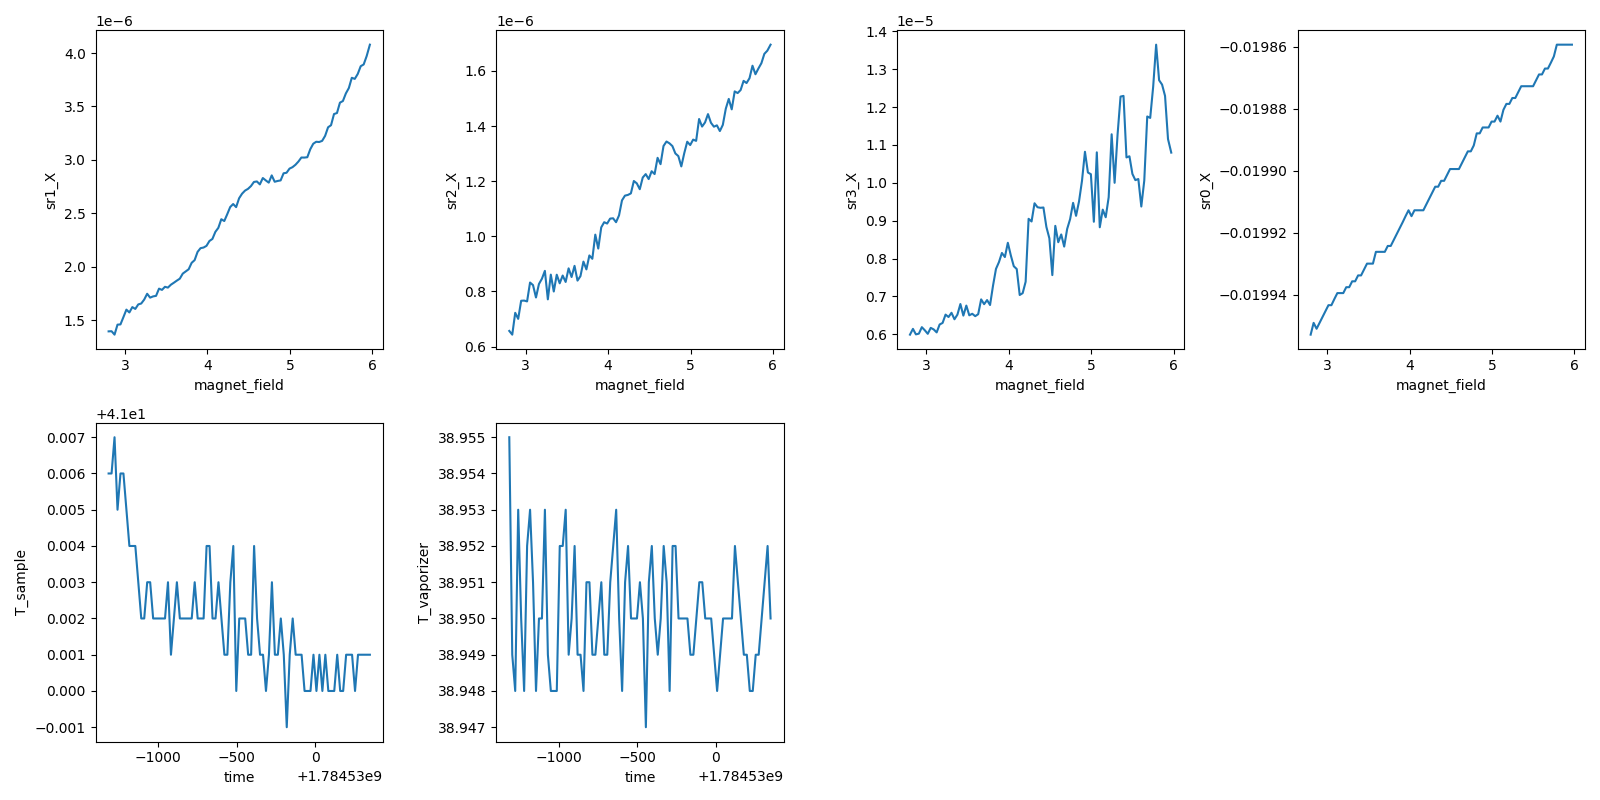

2026-07-19 23:52:29,411 [INFO] Completed in 0h 27m 46s


2026-07-19 23:52:29,412 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260718-QC0426\data\21\data.tsv.gz


rung 41K sweep done; B at +2.80 T
LADDER v2 TOP RUNG DONE — HOLDING at 41 K, heaters ON.
HERA: re-fit ML amplitude now; execute EXACTLY ONE of the next two cells (extend 50 K | shutdown).


In [29]:
# === LK ladder v2 — X-designed rungs {base,10,15,21,29,41} K; ends HOLDING at 41 K (extend-while-hot) ===
# recipes: temperature-dependence Flavor B + temperature-dependence-vti guard set; new X-design rule
import os

# --- preconditions ---
_Ts, _B = T_sample(), magnet.field()
print(f"preconditions: T_sample={_Ts:.3f} K (expect base after park), B={_B:+.4f} T (expect ~0), "
      f"heater ranges={heater.sample_range()}/{heater.vaporizer_range()} (expect 0/0)")
assert 1.0 <= _Ts <= 1.6, f"not at base T: {_Ts:.3f} K"
assert abs(_B) <= 0.05, f"field not parked at 0: {_B:+.4f} T"
assert heater.sample_range() == 0 and heater.vaporizer_range() == 0, "heaters not off at ladder start"

vtg_pt, vbg_pt = d0_point(6.0)
k_tg.volt(vtg_pt); k_bg.volt(vbg_pt)
interruptible_sleep(10)
print(f"gates at ({k_tg.volt():+.3f}, {k_bg.volt():+.3f}) (n=6.0e12, D=0 electron point)")

# sensitivities as v1 (comparability)
sr1.sensitivity(1e-5); sr2.sensitivity(5e-6); sr3.sensitivity(1e-4); sr0.sensitivity(5e-2)

B_LO, B_HI, DB = 2.8, 6.0, 0.036
B_up = np.arange(B_LO, B_HI + 1e-9, DB)
RUNGS = [None, 10.0, 15.0, 21.0, 29.0, 41.0]   # None = base; X_ML ~ 0.73,1.10,1.54,2.12,3.00

_lf = [p for p in VTI.temp_logfile_candidates["T_sample"] if os.path.exists(p)][0]

def _fresh():
    age = time.time() - os.path.getmtime(_lf)
    assert age < 15, f"T logfile stale ({age:.0f} s) — worker dead? aborting ladder"

def wait_hover(target, tv_start, timeout_s=2400):
    t0 = time.time()
    hist = []
    while time.time() - t0 < timeout_s:
        _fresh()
        T_now, Tv_now = T_sample(), T_vaporizer()
        hist.append((time.time(), T_now))
        if Tv_now > max(tv_start, target) + 2.0:
            heater.off('both')
            raise RuntimeError(f"runaway: T_vap={Tv_now:.2f} K; heaters off")
        recent = [h for h in hist if h[0] > time.time() - 90]
        if len(recent) >= 7:
            Ts_r = [h[1] for h in recent]
            if (max(Ts_r) - min(Ts_r) < 0.1) and (target - 0.5 <= T_now <= target + 3.0):
                return T_now
        interruptible_sleep(10)
    heater.off('both')
    raise RuntimeError(f"hover timeout at {target} K; heaters off")

magnet.field(B_LO)   # blocking ramp 0 -> 2.8 T (~20 min)

for rung in RUNGS:
    tv_start = T_vaporizer()
    if rung is not None:
        heater.set_both(rung, ratio=0.95)
        interruptible_sleep(5)
        assert heater.sample_range() > 0 and heater.vaporizer_range() > 0, "set_both did not enable ranges"
        T_acc = wait_hover(rung, tv_start)
        print(f"rung {rung} K accepted at T={T_acc:.3f} K (hover)")
    else:
        print(f"rung base: T={T_sample():.3f} K")

    _Bnow = magnet.field()
    vec = B_up if abs(_Bnow - B_LO) < abs(_Bnow - B_HI) else B_up[::-1]
    if abs(magnet.field() - vec[0]) > 0.05:
        magnet.field(vec[0])

    lab = f"{rung:.0f}K" if rung is not None else "base2"
    meas_config["comments"] = (f"temperature-dependence-vti Flavor B (LK v2, X-designed): rung {lab}, "
                               f"n=6.0e12 D=0 electron, B {vec[0]:.1f}->{vec[-1]:.1f} T x{len(vec)}, I_bias=20 nA")
    s = sweep.AsyncStation(meas_config)
    s.add_comment('temperature-dependence-vti')
    s.add_comment(f'LK ladder v2 rung {lab}: top X>=3 for m_ML=0.019 at B_eff=3.82 (new X-design rule); '
                  f'fixed point Vtg={vtg_pt:+.3f} Vbg={vbg_pt:+.3f}; base2 doubles as repro check vs run 10')
    s.fp(T_sample).fp(T_vaporizer)
    s.fp(magnet.field)
    s.fp(k_tg.volt).fp(k_tg.curr)
    s.fp(k_bg.volt).fp(k_bg.curr)
    for _l in (sr0, sr1, sr2, sr3):
        s.fp(_l.X).fp(_l.P)
    s.plot(magnet.field, sr1.X)
    s.plot(magnet.field, sr2.X)
    s.plot(magnet.field, sr3.X)
    s.plot(magnet.field, sr0.X)
    s.plot('time', T_sample)
    s.plot('time', T_vaporizer)
    s.sweep(magnet.field, vec, delay=0)
    print(f"rung {lab} sweep done; B at {magnet.field():+.2f} T")

print("LADDER v2 TOP RUNG DONE — HOLDING at 41 K, heaters ON.")
print("HERA: re-fit ML amplitude now; execute EXACTLY ONE of the next two cells (extend 50 K | shutdown).")


preconditions: T=41.00 K (expect ~41, still hot), ranges 2/2 (expect on)


rung 50 K accepted at T=50.005 K
2026-07-19 23:56:23,733 [INFO] Starting sweep with ID 22


2026-07-19 23:56:23,734 [INFO] Minimum duration 0h 0m 0s


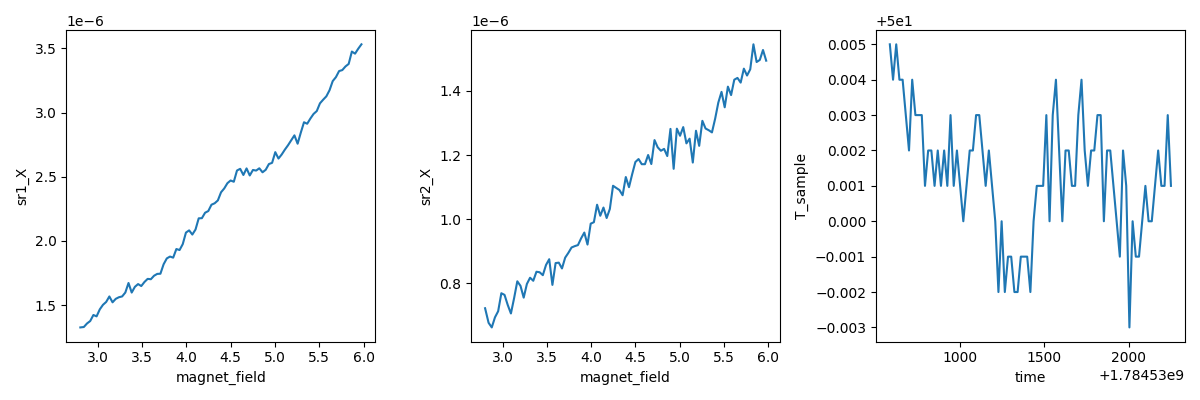

2026-07-20 00:24:10,502 [INFO] Completed in 0h 27m 45s


2026-07-20 00:24:10,503 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260718-QC0426\data\22\data.tsv.gz


extension rung done; run shutdown cell next


In [30]:
# === LK ladder v2 — CONDITIONAL extension rung 50 K (X_ML ~ 3.7); run only on HERA's re-fit decision ===
_Ts = T_sample()
print(f"preconditions: T={_Ts:.2f} K (expect ~41, still hot), ranges {heater.sample_range()}/{heater.vaporizer_range()} (expect on)")
assert _Ts > 35.0, f"not holding hot ({_Ts:.1f} K) — extend-while-hot window missed; do not re-heat, run shutdown"
assert heater.sample_range() > 0, "heaters not on"

tv_start = T_vaporizer()
heater.set_both(50.0, ratio=0.95)
T_acc = wait_hover(50.0, tv_start)          # helper from the ladder cell (same kernel)
print(f"rung 50 K accepted at T={T_acc:.3f} K")

_Bnow = magnet.field()
vec = np.arange(2.8, 6.0 + 1e-9, 0.036)
vec = vec if abs(_Bnow - 2.8) < abs(_Bnow - 6.0) else vec[::-1]
meas_config["comments"] = ("temperature-dependence-vti Flavor B (LK v2 extension): rung 50K, n=6.0e12 D=0, "
                           f"B {vec[0]:.1f}->{vec[-1]:.1f} T x{len(vec)}, I_bias=20 nA")
s = sweep.AsyncStation(meas_config)
s.add_comment('temperature-dependence-vti')
s.add_comment('LK ladder v2 extension rung 50K (X_ML~3.7), extend-while-hot')
s.fp(T_sample).fp(T_vaporizer)
s.fp(magnet.field)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
for _l in (sr0, sr1, sr2, sr3):
    s.fp(_l.X).fp(_l.P)
s.plot(magnet.field, sr1.X)
s.plot(magnet.field, sr2.X)
s.plot('time', T_sample)
s.sweep(magnet.field, vec, delay=0)
print("extension rung done; run shutdown cell next")


In [ ]:
# === LK ladder v2 — shutdown: heaters off, passive return to base; park field + gates ===
heater.off('both')
print(f"heaters off at T={T_sample():.2f} K; passive descent to base")
k_tg.volt(0); k_bg.volt(0)
magnet.field(0.0)   # blocking ~23 min from 6 T / ~0 from 2.8 depending on last leg
print(f"parked: B={magnet.field():+.4f} T, gates (0,0), T={T_sample():.2f} K (descending), DC205 {dc205.voltage():+.3f} V")


heaters off at T=50.02 K; passive descent to base


In [33]:
heater.set_both(100.0, ratio=1/3)